# RGB+ELA U-Net 압축 격자 깨기 증강 + 정상 이미지 포함 실험

- 작성자: kimjihwan
- 상태: **작성 중**
- 작성일: 2026-11-25
- 관련 작업: T14 JPEG 증강(제안서 이후 추가 실험)
- [보고서](../../docs/rgb_ela_unet/EXP_kimjihwan_007_rgb_ela_unet_grid_break.md) · 비교 기준: [005 JPEG 증강](../../docs/rgb_ela_unet/EXP_kimjihwan_005_rgb_ela_unet_jpeg_aug.md) · [004 RGB+ELA U-Net](../../docs/rgb_ela_unet/EXP_kimjihwan_004_rgb_ela_unet_baseline.md) · 근거: [006 압축 흔적 측정](../../docs/eda/EXP_kimjihwan_006_compression_trace_check.md)

## 목적·가설

006에서 AutoSplice 조작본은 마스크 밖에만 Q75 압축 흔적이 남아 학습 없이도 위치를 찾을 수 있고(AUC 0.92), CocoGlide에는 8×8 격자 흔적이 없으며 마스크 밖 픽셀이 원본과 같은 부분 편집임을 확인함. 004·005는 CocoGlide JPEG100에서 이미지 전체를 칠했고 위치 정보가 없었음(픽셀 AUC 0.53~0.56). 005는 이미지 전체가 재압축된 CocoGlide JPEG90·75에서만 약한 위치 정보를 보였음(픽셀 AUC 0.61~0.69, 장면 내용을 뺀 쌍 차이 AUC 0.55~0.59).

가설: 학습 중에 압축 격자를 깨서 "압축 흔적 유무"라는 지름길을 끄고, 흔적이 없는 정상 이미지를 함께 학습하면, CocoGlide JPEG100에서 이미지 전체 칠하기가 줄고 위치 정보가 생김.

**성공 기준(실행 전 고정):** CocoGlide JPEG100에서 (1) 정상 오탐률이 005(0.957)보다 확실히 낮고, (2) 픽셀 AUC와 쌍 차이 AUC가 0.5를 확실히 넘음. AutoSplice 성능 하락 폭도 함께 보고함. F1만으로 판단하지 않음.

## 005에서 바꾼 점

- **격자 깨기 증강:** 샘플마다 확률 0.5로, JPEG 재저장 전에 원본 전체를 (a) 0.6~1.0배 무작위 축소(이미지 bicubic, 마스크 nearest, 짧은 변 256 이상 유지) 또는 (b) 8의 배수가 아닌 1~7픽셀 이동(위·왼쪽을 잘라냄) 중 하나로 바꿈. 이 경우 재저장 서브샘플링도 4:2:0·4:4:4 중 무작위로 고름(CocoGlide 평가 입력은 4:4:4). 006 대조 확인에서 두 변환 모두 Q75 흔적을 없앴음(정렬도 0.255·0.259).
- **정상 이미지 포함:** train 정상 원본(빈 마스크)을 조작 이미지와 함께 학습함. 같은 증강을 적용함.
- 나머지(재저장 품질 70~100, 원본 전체 재저장 → ELA → 크롭 → 반전, 모델, 손실, 학습 예산, 선택 기준 `best_mean`·`best_q100`, 평가)는 005와 같음. 위치 진단 지표(픽셀 AUC, 마스크 섞기 F1, 쌍 차이 AUC)는 처음부터 포함함.

팀원이 VS Code의 Colab 원격 커널(GPU)에서 위에서부터 실행하고 출력이 포함된 노트북을 저장함. 학습 셀은 끊겨도 다시 실행하면 이어서 학습함. 004·005 결과는 각 실행 폴더에 저장된 값을 불러와 비교함.

## 1. Drive·공통 코드·실행 환경 준비

공유 Drive의 `AI_Forensics/datasets/`와 `AI_Forensics/project/scripts/`를 읽음. 학습 기록·재시작 파일은 개인 폴더 `MyDrive/AI_Forensics_runs/kimjihwan/`에 저장하고, 대표 최선 체크포인트는 팀 규칙대로 공유 Drive `AI_Forensics/project/models/checkpoints/rgb_ela_unet/`에 자동 보관함. 데이터·가중치는 Git에 올리지 않음.

In [1]:
from pathlib import Path
from google.colab import drive
from io import BytesIO
import hashlib
import importlib
import importlib.metadata
import json
import os
import platform
import random
import shutil
import sys
import time
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, features
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.models import resnet50, ResNet50_Weights

drive.mount("/content/drive")
shared_root = Path("/content/drive/MyDrive/AI_Forensics")
project_root = shared_root / "project"
work_root = Path("/content")
data_root = work_root / "datasets"
experiment_name = "EXP_kimjihwan_007_rgb_ela_unet_grid_break"
run_root = Path("/content/drive/MyDrive/AI_Forensics_runs/kimjihwan") / experiment_name
local_ckpt_root = work_root / "checkpoints" / experiment_name
shared_ckpt_path = project_root / "models/checkpoints/rgb_ela_unet" / f"{experiment_name}_best.pt"
ref005_dir = Path("/content/drive/MyDrive/AI_Forensics_runs/kimjihwan/EXP_kimjihwan_005_rgb_ela_unet_jpeg_aug")
ref004_dir = Path("/content/drive/MyDrive/AI_Forensics_runs/kimjihwan/EXP_kimjihwan_004_rgb_ela_unet_baseline/bce_dice")
split_path = project_root / "scripts/splits/autosplice_seed42.csv"
archive_paths = {
    "AutoSplice": shared_root / "datasets/AutoSplice/AutoSplice.zip",
    "CocoGlide": shared_root / "datasets/CocoGlide.zip",
}
extract_paths = {"AutoSplice": data_root, "CocoGlide": data_root / "CocoGlide"}
required = ["scripts/__init__.py", "scripts/datasets.py", "scripts/preprocessing.py", "scripts/evaluation.py",
            "scripts/splits/autosplice_seed42.csv"]
for relative in required:
    if not (project_root / relative).is_file():
        raise FileNotFoundError(f"Drive에 공통 파일을 업로드해야 함: {relative}")

sys.path.insert(0, str(project_root))
importlib.invalidate_caches()
import scripts
import scripts.datasets as dataset_module
import scripts.preprocessing as preprocessing_module
import scripts.evaluation as evaluation_module

for module, relative in [(scripts, "scripts/__init__.py"), (dataset_module, "scripts/datasets.py"),
                         (preprocessing_module, "scripts/preprocessing.py"), (evaluation_module, "scripts/evaluation.py")]:
    if Path(module.__file__).resolve() != (project_root / relative).resolve():
        raise ImportError(f"프로젝트의 모듈을 불러오도록 커널을 재시작해야 함: {relative}")
    print("불러온 코드:", module.__file__)

from scripts.datasets import sha256, prepare_dataset_zip, autosplice_records, cocoglide_records
from scripts.preprocessing import load_rgb, load_binary_mask, crop_pair, make_ela, pad_image, unpad_image
from scripts.evaluation import confusion_counts, pixel_f1, iou, false_positive_rate

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("실행 시각 UTC:", datetime.now(timezone.utc).isoformat())
print("Python:", platform.python_version())
print("OS:", platform.platform())
for package in ("numpy", "Pillow", "pandas", "matplotlib", "torch", "torchvision"):
    print(package, importlib.metadata.version(package))
print("JPEG library:", features.version("jpg"))
print("CUDA:", torch.version.cuda, "/ cuDNN:", torch.backends.cudnn.version())
print("TF32 matmul / cuDNN:", torch.backends.cuda.matmul.allow_tf32, torch.backends.cudnn.allow_tf32)
print("CPU 코어:", os.cpu_count())
print("장치:", device)
if device.type != "cuda":
    raise RuntimeError("GPU 런타임에서 실행해야 함.")
properties = torch.cuda.get_device_properties(0)
print("GPU:", properties.name, f"{properties.total_memory / 1024**3:.1f} GiB")
print("실행 기록 폴더:", run_root)
print("공유 체크포인트:", shared_ckpt_path)

Mounted at /content/drive
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/__init__.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/datasets.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/preprocessing.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/evaluation.py
실행 시각 UTC: 2026-11-24T16:34:37.352299+00:00
Python: 3.13.16
OS: Linux-6.6.159+-x86_64-with-glibc2.39
numpy 2.4.6
Pillow 11.3.0
pandas 2.2.3
matplotlib 3.10.0
torch 2.14.1+cu130
torchvision 0.29.1+cu130
JPEG library: 6.2
CUDA: 13.0 / cuDNN: 92800
TF32 matmul / cuDNN: False True
CPU 코어: 8
장치: cuda
GPU: Tesla T4 14.6 GiB
실행 기록 폴더: /content/drive/MyDrive/AI_Forensics_runs/kimjihwan/EXP_kimjihwan_007_rgb_ela_unet_grid_break
공유 체크포인트: /content/drive/MyDrive/AI_Forensics/project/models/checkpoints/rgb_ela_unet/EXP_kimjihwan_007_rgb_ela_unet_grid_break_best.pt


In [2]:
# Git 저장소의 LF 줄바꿈 기준 해시임. Windows에서 CRLF로 바뀐 파일을 올리면 일치하지 않음.
expected_files = {
    "scripts/__init__.py": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855",
    "scripts/datasets.py": "435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88",
    "scripts/preprocessing.py": "73ce7fa0aee3f2b901a9ab04d430ff8ae2bcaa7262005600f6b08f04b95c652f",
    "scripts/evaluation.py": "ad400aa2cf453bd54ecc3e73abc38bc80cb1f7239eea7489b3072dae96dfcb52",
    "scripts/splits/autosplice_seed42.csv": "f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e",
}
for relative, expected_hash in expected_files.items():
    actual_hash = sha256(project_root / relative)
    print(relative, actual_hash)
    if actual_hash != expected_hash:
        raise ValueError(f"검토한 코드·분할 버전과 일치해야 함: {relative}")

seed = 42
config = dict(
    input_mode="rgb_ela", in_channels=6, ela_quality=90, ela_scale=15, ela_subsampling=2, ela_order="full-image ELA -> crop -> flip",
    mask_foreground=255, train_quality=100, train_kinds=["manipulated", "normal"],
    crop_size=256, crop_stride=16, flip_probability=0.5,
    encoder="torchvision resnet50", encoder_weights="IMAGENET1K_V2", normalization="RGB and ELA each /255 then ImageNet mean/std", conv1="6ch: RGB pretrained weights copied to ELA channels, no rescale",
    loss="bce_dice", optimizer="Adam", learning_rate=1e-4, batch_size=16, num_workers=4,
    max_epochs=30, patience=5,
    augmentation="JPEG recompress every sample", aug_quality_min=70, aug_quality_max=100, aug_subsampling=2,
    aug_order="(grid break) -> full-image JPEG recompress -> full-image ELA -> crop -> flip",
    grid_break_probability=0.5, grid_break_ops="resize U(0.6,1.0) bicubic/mask nearest, short side>=256 | shift 1-7px (dy,dx not both 0), 50/50",
    grid_break_subsampling=[0, 2],
    sample_rng="numpy default_rng([seed, epoch, index]) for break, quality, subsampling, crop, flip", loader_seed="seed*1000+epoch",
    val_qualities=[100, 90, 75], selection="best_mean: mean of val manipulated F1 over JPEG100/90/75 (patience); best_q100: val JPEG100 F1",
    dice_eps=1.0, threshold=0.5, pad_multiple=32, pad_mode="pad_image/unpad_image (bottom-right zero, pixel 0)",
    cocoglide_jpeg_qualities=[100, 90, 75], cocoglide_jpeg_subsampling=0, seed=seed,
)
config_hash = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:12]
for key, value in config.items():
    print(f"{key}: {value}")
print("설정 해시:", config_hash)


def set_seed(value):
    random.seed(value)
    np.random.seed(value)
    torch.manual_seed(value)
    torch.cuda.manual_seed_all(value)


set_seed(seed)
torch.backends.cudnn.benchmark = False

scripts/__init__.py e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855
scripts/datasets.py 435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88
scripts/preprocessing.py 73ce7fa0aee3f2b901a9ab04d430ff8ae2bcaa7262005600f6b08f04b95c652f
scripts/evaluation.py ad400aa2cf453bd54ecc3e73abc38bc80cb1f7239eea7489b3072dae96dfcb52
scripts/splits/autosplice_seed42.csv f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e
input_mode: rgb_ela
in_channels: 6
ela_quality: 90
ela_scale: 15
ela_subsampling: 2
ela_order: full-image ELA -> crop -> flip
mask_foreground: 255
train_quality: 100
train_kinds: ['manipulated', 'normal']
crop_size: 256
crop_stride: 16
flip_probability: 0.5
encoder: torchvision resnet50
encoder_weights: IMAGENET1K_V2
normalization: RGB and ELA each /255 then ImageNet mean/std
conv1: 6ch: RGB pretrained weights copied to ELA channels, no rescale
loss: bce_dice
optimizer: Adam
learning_rate: 0.0001
batch_size: 16
num_workers: 4
max_epochs: 30
pati

## 2. 데이터 준비

두 ZIP을 해시 확인 후 해제함. 학습은 train 조작 이미지(JPEG 100)와 train 정상 원본(빈 마스크), 검증은 val 조작 361장을 JPEG 100·90·75에서 각각(F1·IoU), val 정상 227장은 한 번(오탐률 기록) 사용함.

테스트는 AutoSplice test 조작본 JPEG 100·90·75와 정상 원본(한 번), CocoGlide 조작·정상을 PNG에서 JPEG 100·90·75(4:4:4)로 변환한 입력으로 구성함. CocoGlide 정답 비교는 원본 크기 마스크로 함.

In [3]:
archive_hashes = {
    "AutoSplice": "0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36",
    "CocoGlide": "fc848643ad0a81010ba2a6ab8c055762782f54e4fb9e407210dbfe1c3b538af9",
}
for name, source in archive_paths.items():
    prepare_dataset_zip(source, work_root / f"{name}.zip", extract_paths[name], archive_hashes[name])

records_by_quality = {q: autosplice_records(data_root / "AutoSplice", split_path, quality=q) for q in (100, 90, 75)}
base = records_by_quality[100]
train_records = [r for r in base if r["split"] == "train" and r["kind"] in ("manipulated", "normal")]
for record in train_records:
    record["input_path"] = record["image_path"]
val_manipulated = {q: [dict(r, variant=f"JPEG{q}", input_path=r["image_path"]) for r in records
                       if r["split"] == "val" and r["kind"] == "manipulated"] for q, records in records_by_quality.items()}
val_normal = [dict(r, variant="original", input_path=r["image_path"]) for r in base if r["split"] == "val" and r["kind"] == "normal"]

test_records = []
for quality, records in records_by_quality.items():
    for record in records:
        if record["split"] != "test" or (record["kind"] == "normal" and quality != 100):
            continue
        variant = "original" if record["kind"] == "normal" else f"JPEG{quality}"
        test_records.append(dict(record, variant=variant, input_path=record["image_path"], input_conversion="none"))

cocoglide_root = data_root / "CocoGlide"
for quality in config["cocoglide_jpeg_qualities"]:
    jpeg_root = work_root / "unet_inputs" / f"CocoGlide_JPEG{quality}_444"
    converted = 0
    for record in cocoglide_records(cocoglide_root):
        source = record["image_path"]
        target = (jpeg_root / source.relative_to(cocoglide_root)).with_suffix(".jpg")
        target.parent.mkdir(parents=True, exist_ok=True)
        with Image.open(source) as image:
            if image.format != "PNG":
                raise ValueError(f"CocoGlide 원본은 PNG여야 함: {source}")
            size = image.size
            image.convert("RGB").save(target, format="JPEG", quality=quality, subsampling=config["cocoglide_jpeg_subsampling"])
        with Image.open(target) as image:
            if image.format != "JPEG" or image.size != size:
                raise ValueError(f"변환 형식과 원본 크기가 일치해야 함: {target}")
        converted += 1
        test_records.append(dict(record, variant=f"JPEG{quality}_444", input_path=target,
                                 input_conversion=f"PNG_to_JPEG{quality}_444"))
    if converted != 1024:
        raise ValueError("CocoGlide 변환 수는 품질마다 1,024장이어야 함.")

if pd.Series([str(r["input_path"]) for r in test_records]).duplicated().any():
    raise ValueError("테스트 목록에 같은 입력 파일이 중복되지 않아야 함.")
assert {r["split"] for r in train_records} == {"train"} and {r["kind"] for r in train_records} == {"manipulated", "normal"}
assert all(len(v) == len(val_manipulated[100]) for v in val_manipulated.values())

print("학습 이미지:", pd.Series([r["kind"] for r in train_records]).value_counts().to_dict())
print("val 조작 이미지(품질별):", {q: len(v) for q, v in val_manipulated.items()}, "/ val 정상:", len(val_normal))
test_table = pd.DataFrame(test_records)
display(test_table.groupby(["dataset", "split", "variant", "input_conversion", "kind"]).size().rename("images").reset_index())
print("테스트 이미지 합계:", len(test_records))

AutoSplice ZIP SHA-256 확인 및 압축 해제 완료
CocoGlide ZIP SHA-256 확인 및 압축 해제 완료
학습 이미지: {'manipulated': 2925, 'normal': 1818}
val 조작 이미지(품질별): {100: 361, 90: 361, 75: 361} / val 정상: 227


,dataset,split,variant,input_conversion,kind,images
0,AutoSplice,test,JPEG100,none,manipulated,335
1,AutoSplice,test,JPEG75,none,manipulated,335
2,AutoSplice,test,JPEG90,none,manipulated,335
3,AutoSplice,test,original,none,normal,228
4,CocoGlide,external_test,JPEG100_444,PNG_to_JPEG100_444,manipulated,512
5,CocoGlide,external_test,JPEG100_444,PNG_to_JPEG100_444,normal,512
6,CocoGlide,external_test,JPEG75_444,PNG_to_JPEG75_444,manipulated,512
7,CocoGlide,external_test,JPEG75_444,PNG_to_JPEG75_444,normal,512
8,CocoGlide,external_test,JPEG90_444,PNG_to_JPEG90_444,manipulated,512
9,CocoGlide,external_test,JPEG90_444,PNG_to_JPEG90_444,normal,512


테스트 이미지 합계: 4305


## 3. 학습 입력 구성

샘플마다 `(시드, epoch, 샘플 번호)`로 만든 난수에서 격자 깨기 여부·방식, 품질 q(70~100), 서브샘플링, 크롭 위치(16의 배수 좌표), 반전 여부를 뽑음. 격자 깨기가 뽑히면 원본 전체를 축소하거나 1~7픽셀 이동한 뒤 q로 다시 저장하고(서브샘플링 4:2:0·4:4:4 무작위), 아니면 005와 같이 q·4:2:0으로 다시 저장함. 다시 저장한 RGB에서 ELA를 계산하고 RGB·ELA·마스크를 같은 256×256으로 잘라 같이 반전함. 크롭 좌표는 바뀐 이미지 기준 16의 배수임.

샘플 0의 epoch 1~5 품질: [83, 71, 92, 98, 73]
배치 입력 (16, 6, 256, 256) torch.float32 / 마스크 (16, 1, 256, 256) torch.float32 [0.0, 1.0]
배치 품질: [84, 94, 85, 100, 79, 85, 100, 86, 100, 79, 91, 96, 73, 94, 85, 71] / 격자 깨기: [False, False, True, True, True, False, True, True, True, True, False, False, False, True, False, True]
epoch당 step: 296


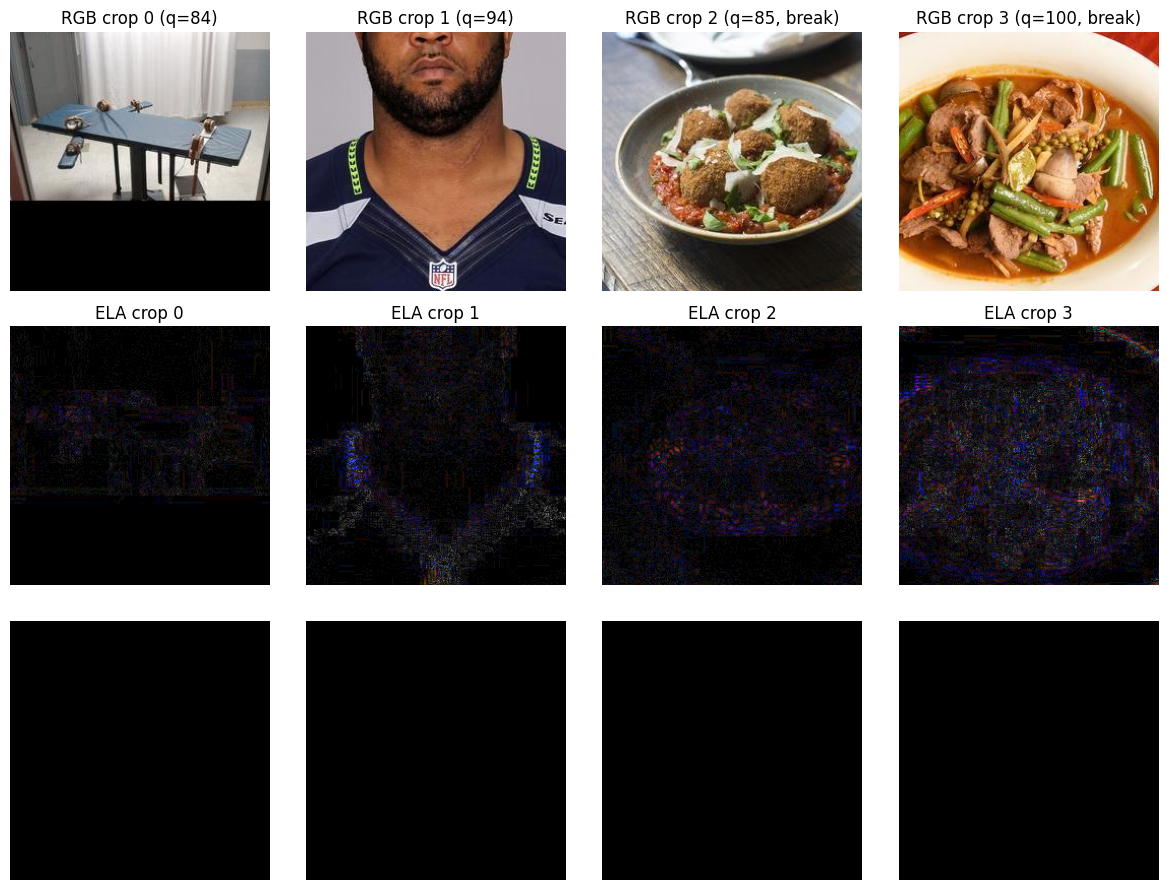

In [4]:
imagenet_mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
imagenet_std = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def load_pair(record):
    rgb = load_rgb(record["input_path"])
    if record["kind"] == "normal":
        mask = np.zeros(rgb.shape[:2], dtype=np.uint8)
    else:
        mask = load_binary_mask(record["mask_path"], foreground_value=config["mask_foreground"])
    if rgb.shape[:2] != mask.shape:
        raise ValueError(f"이미지와 마스크 크기가 같아야 함: {record['input_path']}")
    return rgb, mask


def ela_of(rgb):
    return make_ela(rgb, quality=config["ela_quality"], scale=config["ela_scale"], subsampling=config["ela_subsampling"])


def jpeg_recompress(rgb, quality, subsampling=None):
    subsampling = config["aug_subsampling"] if subsampling is None else subsampling
    with BytesIO() as buffer:
        Image.fromarray(rgb).save(buffer, format="JPEG", quality=int(quality), subsampling=int(subsampling),
                                  optimize=False, progressive=False)
        buffer.seek(0)
        with Image.open(buffer) as image:
            return np.array(image.convert("RGB"), dtype=np.uint8)


def to_input(rgb, ela):
    parts = [(part.astype(np.float32) / 255.0 - imagenet_mean) / imagenet_std for part in (rgb, ela)]
    return torch.from_numpy(np.concatenate(parts, axis=2).transpose(2, 0, 1).copy())


def break_grid(rgb, mask, rng):
    if rng.random() < 0.5 or min(rgb.shape[:2]) - 7 < config["crop_size"]:
        short = min(rgb.shape[:2])
        factor = max(float(rng.uniform(0.6, 1.0)), config["crop_size"] / short)
        size = (max(config["crop_size"], round(rgb.shape[1] * factor)), max(config["crop_size"], round(rgb.shape[0] * factor)))
        rgb = np.array(Image.fromarray(rgb).resize(size, Image.BICUBIC))
        mask = np.array(Image.fromarray(mask).resize(size, Image.NEAREST))
        return rgb, mask, "resize"
    dy, dx = 0, 0
    while dy == 0 and dx == 0:
        dy, dx = int(rng.integers(0, 8)), int(rng.integers(0, 8))
    return rgb[dy:, dx:].copy(), mask[dy:, dx:].copy(), "shift"


def augment_full(rgb, mask, rng):
    broken = rng.random() < config["grid_break_probability"]
    operation = "none"
    if broken:
        rgb, mask, operation = break_grid(rgb, mask, rng)
    quality = int(rng.integers(config["aug_quality_min"], config["aug_quality_max"] + 1))
    subsampling = int(rng.choice(config["grid_break_subsampling"])) if broken else config["aug_subsampling"]
    return jpeg_recompress(rgb, quality, subsampling), mask, quality, operation


class AugmentedTrainCrops(torch.utils.data.Dataset):
    def __init__(self, records, epoch):
        self.records, self.epoch = records, epoch

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        rng = np.random.default_rng([seed, self.epoch, index])
        rgb, mask = load_pair(self.records[index])
        rgb, mask, quality, operation = augment_full(rgb, mask, rng)
        ela = ela_of(rgb)
        size, stride = config["crop_size"], config["crop_stride"]
        top = int(rng.integers(0, (rgb.shape[0] - size) // stride + 1)) * stride
        left = int(rng.integers(0, (rgb.shape[1] - size) // stride + 1)) * stride
        rgb, mask = crop_pair(rgb, mask, top=top, left=left, height=size, width=size)
        ela = ela[top:top + size, left:left + size].copy()
        if rng.random() < config["flip_probability"]:
            rgb, ela, mask = rgb[:, ::-1].copy(), ela[:, ::-1].copy(), mask[:, ::-1].copy()
        return to_input(rgb, ela), torch.from_numpy(mask[None].astype(np.float32)), quality, operation != "none"


def make_train_loader(epoch):
    generator = torch.Generator().manual_seed(seed * 1000 + epoch)
    return torch.utils.data.DataLoader(AugmentedTrainCrops(train_records, epoch), batch_size=config["batch_size"],
                                       shuffle=True, drop_last=True, num_workers=config["num_workers"],
                                       generator=generator, pin_memory=True)


dataset_check = AugmentedTrainCrops(train_records, epoch=1)
a, b = dataset_check[0], dataset_check[0]
assert torch.equal(a[0], b[0]) and torch.equal(a[1], b[1]) and a[2:] == b[2:], "같은 epoch·샘플은 같은 증강이어야 함."
qualities_check = [AugmentedTrainCrops(train_records, epoch=e)[0][2] for e in range(1, 6)]
assert all(config["aug_quality_min"] <= q <= config["aug_quality_max"] for q in qualities_check)
print("샘플 0의 epoch 1~5 품질:", qualities_check)

x, y, q, broken = next(iter(make_train_loader(1)))
print("배치 입력", tuple(x.shape), x.dtype, "/ 마스크", tuple(y.shape), y.dtype, torch.unique(y).tolist())
print("배치 품질:", q.tolist(), "/ 격자 깨기:", broken.tolist())
print("epoch당 step:", len(train_records) // config["batch_size"])

figure, axes = plt.subplots(3, 4, figsize=(12, 9))
for column in range(4):
    axes[0, column].imshow((x[column, :3].numpy().transpose(1, 2, 0) * imagenet_std + imagenet_mean).clip(0, 1))
    axes[1, column].imshow((x[column, 3:].numpy().transpose(1, 2, 0) * imagenet_std + imagenet_mean).clip(0, 1))
    axes[2, column].imshow(y[column, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[0, column].set_title(f"RGB crop {column} (q={int(q[column])}{', break' if bool(broken[column]) else ''})")
    axes[1, column].set_title(f"ELA crop {column}")
    for row in range(3):
        axes[row, column].axis("off")
plt.tight_layout()
plt.show()

## 4. 증강 확인

학습 조작 이미지 한 장에 증강 없음, q=85 재저장(005 방식), 축소 후 q=85, 1~7픽셀 이동 후 q=85를 적용하고, 마스크 안·밖 ELA 평균과 006과 같은 Q75 격자 정렬도(안·밖)를 비교함. 격자 깨기를 적용하면 안·밖 모두 정렬도가 약 0.25(흔적 없음)가 돼야 함.

확인 이미지: 39406_0.jpg / 마스크 비율 0.0848
q75_inside·outside는 RGB에서 다시 구한 휘도 기준이라 006의 디코더 휘도 값과 조금 다를 수 있음


,setting,size,ela_inside,ela_outside,q75_inside,q75_outside
0,no aug (JPEG100 file),374x256,40.776,16.689,0.249,0.159
1,q=85 (005),374x256,24.387,14.463,0.262,0.215
2,resize x1.00 -> q=85,374x256,24.387,14.463,0.262,0.215
3,"shift 3,5 -> q=85",369x253,24.628,23.486,0.260,0.267


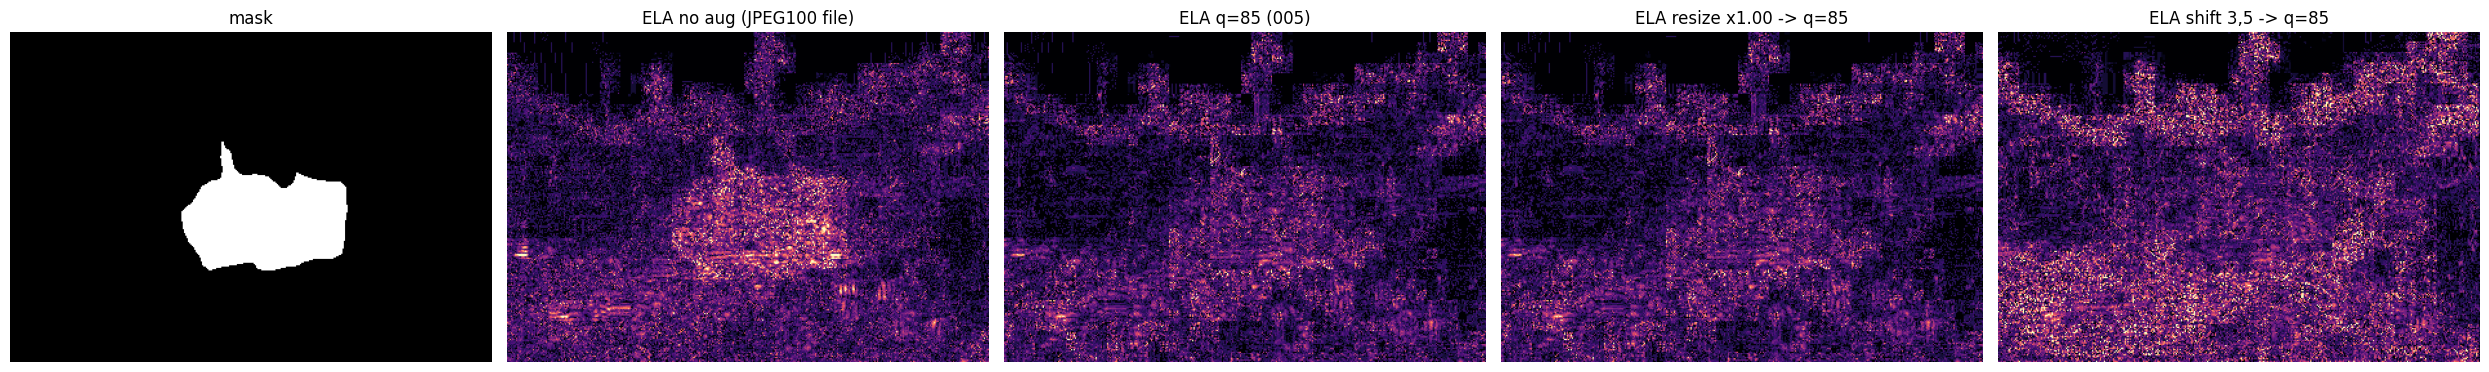

In [5]:
from scipy.fft import dctn


def q75_alignment(rgb, region):
    y = np.asarray(Image.fromarray(rgb).convert("YCbCr"), dtype=np.float64)[..., 0]
    h, w = (y.shape[0] // 8) * 8, (y.shape[1] // 8) * 8
    blocks = (y[:h, :w] - 128.0).reshape(h // 8, 8, w // 8, 8).swapaxes(1, 2)
    u, v = np.meshgrid(np.arange(8), np.arange(8), indexing="ij")
    select = ((u + v) >= 1) & ((u + v) <= 4)
    with BytesIO() as buffer:
        Image.new("RGB", (16, 16)).save(buffer, format="JPEG", quality=75)
        buffer.seek(0)
        with Image.open(buffer) as image:
            table = np.array(image.quantization[0], dtype=np.float64).reshape(8, 8)[select]
    coefficients = dctn(blocks, axes=(2, 3), norm="ortho")[:, :, select]
    eligible = np.abs(coefficients) >= table / 2
    distance = np.abs(coefficients / table - np.round(coefficients / table))
    score = np.where(eligible.sum(axis=2) >= 3, (distance * eligible).sum(axis=2) / np.maximum(eligible.sum(axis=2), 1), np.nan)
    block_region = region[:h, :w].reshape(h // 8, 8, w // 8, 8).swapaxes(1, 2).mean(axis=(2, 3))
    inside, outside = score[block_region == 1], score[block_region == 0]
    return np.nanmean(inside) if inside.size else np.nan, np.nanmean(outside) if outside.size else np.nan


check_record = next(r for r in train_records[int(np.random.default_rng(seed).integers(len(train_records))):] if r["kind"] == "manipulated")
check_rgb, check_mask = load_pair(check_record)
cases = [("no aug (JPEG100 file)", check_rgb, check_mask)]
cases.append(("q=85 (005)", jpeg_recompress(check_rgb, 85), check_mask))
factor = max(0.8, config["crop_size"] / min(check_rgb.shape[:2]))
resized_size = (round(check_rgb.shape[1] * factor), round(check_rgb.shape[0] * factor))
resized_rgb = np.array(Image.fromarray(check_rgb).resize(resized_size, Image.BICUBIC))
resized_mask = np.array(Image.fromarray(check_mask).resize(resized_size, Image.NEAREST))
cases.append((f"resize x{factor:.2f} -> q=85", jpeg_recompress(resized_rgb, 85), resized_mask))
cases.append(("shift 3,5 -> q=85", jpeg_recompress(check_rgb[3:, 5:].copy(), 85), check_mask[3:, 5:].copy()))
rows, panels = [], []
for label, rgb_case, mask_case in cases:
    ela_case = ela_of(rgb_case).astype(np.float32).mean(axis=2)
    inside = mask_case > 0
    q75_in, q75_out = q75_alignment(rgb_case, inside.astype(np.float64))
    rows.append(dict(setting=label, size=f"{rgb_case.shape[1]}x{rgb_case.shape[0]}", ela_inside=ela_case[inside].mean(),
                     ela_outside=ela_case[~inside].mean(), q75_inside=q75_in, q75_outside=q75_out))
    panels.append((ela_case, label))
print("확인 이미지:", Path(check_record["image_path"]).name, "/ 마스크 비율", round((check_mask > 0).mean(), 4))
print("q75_inside·outside는 RGB에서 다시 구한 휘도 기준이라 006의 디코더 휘도 값과 조금 다를 수 있음")
with pd.option_context("display.float_format", "{:.3f}".format):
    display(pd.DataFrame(rows))

figure, axes = plt.subplots(1, len(panels) + 1, figsize=(5 * (len(panels) + 1), 4))
axes[0].imshow(check_mask, cmap="gray")
axes[0].set_title("mask")
vmax = max(np.percentile(p, 99) for p, _ in panels)
for axis, (ela_case, label) in zip(axes[1:], panels):
    axis.imshow(ela_case, cmap="magma", vmin=0, vmax=vmax)
    axis.set_title(f"ELA {label}")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 5. 모델·손실·평가 함수

모델·손실·평가 함수는 004와 같은 코드임(ResNet-50 U-Net, 6채널 conv1은 RGB 사전학습 가중치를 ELA 쪽에 복사, 이미지별 Dice, 원본 크기 전체 ELA 후 우하단 패딩 추론, 임계값 0.5, 이미지별 평균).

체크포인트는 런타임(`/content/checkpoints/`)에 먼저 저장하고, 임시 이름으로 Drive에 복사한 뒤 SHA-256이 같으면 최종 이름으로 바꿈(팀 보관 규칙).

In [6]:
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels + skip_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
        )

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="nearest")
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        return self.block(x)


class ResNet50UNet(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        encoder = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
        if in_channels == 6:
            rgb_weight = encoder.conv1.weight.detach().clone()
            encoder.conv1 = nn.Conv2d(6, 64, 7, stride=2, padding=3, bias=False)
            with torch.no_grad():
                encoder.conv1.weight.copy_(torch.cat([rgb_weight, rgb_weight], dim=1))
        elif in_channels != 3:
            raise ValueError("입력 채널은 3 또는 6이어야 함.")
        self.stem = nn.Sequential(encoder.conv1, encoder.bn1, encoder.relu)
        self.pool = encoder.maxpool
        self.layers = nn.ModuleList([encoder.layer1, encoder.layer2, encoder.layer3, encoder.layer4])
        self.decoders = nn.ModuleList([
            DecoderBlock(2048, 1024, 256), DecoderBlock(256, 512, 128), DecoderBlock(128, 256, 64),
            DecoderBlock(64, 64, 32), DecoderBlock(32, 0, 16),
        ])
        self.head = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        if x.shape[-2] % 32 or x.shape[-1] % 32:
            raise ValueError("입력 높이·너비는 32의 배수여야 함.")
        stem = self.stem(x)
        features = []
        out = self.pool(stem)
        for layer in self.layers:
            out = layer(out)
            features.append(out)
        out = features[-1]
        for decoder, skip in zip(self.decoders, [features[2], features[1], features[0], stem, None]):
            out = decoder(out, skip)
        return self.head(out)


def dice_per_image(logits, target, eps):
    probability = torch.sigmoid(logits)
    intersection = (probability * target).sum(dim=(1, 2, 3))
    total = probability.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return (1 - (2 * intersection + eps) / (total + eps)).mean()


def compute_loss(condition, logits, target):
    if condition == "bce":
        return F.binary_cross_entropy_with_logits(logits, target)
    if condition == "dice":
        return dice_per_image(logits, target, config["dice_eps"])
    if condition == "bce_dice":
        return F.binary_cross_entropy_with_logits(logits, target) + dice_per_image(logits, target, config["dice_eps"])
    raise ValueError(f"알 수 없는 손실 조건: {condition}")


def predict_full(model, rgb):
    padded_rgb, original_size = pad_image(rgb, multiple=config["pad_multiple"])
    padded_ela, _ = pad_image(ela_of(rgb), multiple=config["pad_multiple"])
    with torch.no_grad():
        logits = model(to_input(padded_rgb, padded_ela)[None].to(device, non_blocking=True))
    probability = torch.sigmoid(logits)[0, 0].float().cpu().numpy()
    return unpad_image(probability, original_size=original_size)


def evaluate(model, records, keep=None):
    model.eval()
    rows, kept = [], {}
    for record in records:
        rgb, mask = load_pair(record)
        probability = predict_full(model, rgb)
        prediction = (probability >= config["threshold"]).astype(np.uint8)
        tp, fp, fn, tn = confusion_counts(mask, prediction)
        row = {k: record.get(k) for k in ("dataset", "split", "variant", "input_conversion", "kind", "original_id")}
        row.update(image=Path(record["image_path"]).name, height=mask.shape[0], width=mask.shape[1],
                   tp=tp, fp=fp, fn=fn, tn=tn, f1=None, iou=None, fpr=None)
        if record["kind"] == "manipulated":
            row.update(f1=pixel_f1(tp, fp, fn), iou=iou(tp, fp, fn))
        else:
            row.update(fpr=false_positive_rate(fp, tn))
        rows.append(row)
        if keep is not None and str(record["input_path"]) in keep:
            kept[str(record["input_path"])] = (rgb, ela_of(rgb), mask, probability)
    frame = pd.DataFrame(rows)
    for column in ("f1", "iou", "fpr"):
        frame[column] = pd.to_numeric(frame[column])
    return (frame, kept) if keep is not None else frame




def verified_copy(source, target):
    target = Path(target)
    target.parent.mkdir(parents=True, exist_ok=True)
    temporary = target.with_name(target.name + ".tmp")
    shutil.copyfile(source, temporary)
    source_hash, copied_hash = sha256(source), sha256(temporary)
    if source_hash != copied_hash:
        temporary.unlink()
        raise IOError(f"복사본 SHA-256이 원본과 달라 교체하지 않음: {target}")
    os.replace(temporary, target)
    return source_hash


def save_checkpoint(payload, name):
    local_ckpt_root.mkdir(parents=True, exist_ok=True)
    local_path = local_ckpt_root / name
    torch.save(payload, local_path)
    verified_copy(local_path, run_root / name)
    return local_path


def copy_to_shared(local_path):
    try:
        file_hash = verified_copy(local_path, shared_ckpt_path)
        return True, file_hash
    except Exception as error:
        print(f"[경고] 공유 Drive 보관 실패, 이전 검증본 유지. 9번 셀에서 다시 시도함: {error}")
        return False, None


def summarize(rows):
    return rows.groupby(["dataset", "kind", "variant"], sort=False).agg(
        images=("image", "size"), pixel_f1=("f1", "mean"), iou=("iou", "mean"), normal_pixel_fpr=("fpr", "mean")).reset_index()


model = ResNet50UNet(6).to(device)
reference_conv1 = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2).conv1.weight.detach().to(device)
assert torch.equal(model.stem[0].weight[:, :3], reference_conv1) and torch.equal(model.stem[0].weight[:, 3:], reference_conv1)
with torch.no_grad():
    for shape in [(2, 6, 256, 256), (1, 6, 256, 384)]:
        assert model(torch.randn(shape, device=device)).shape == (shape[0], 1, shape[2], shape[3])
print("파라미터 수:", sum(p.numel() for p in model.parameters()))
del model, reference_conv1

shared_ckpt_path.parent.mkdir(parents=True, exist_ok=True)
probe_path = shared_ckpt_path.parent / f".{experiment_name}_write_check"
probe_path.write_text("ok")
probe_path.unlink()
print("공유 체크포인트 폴더 쓰기 가능:", shared_ckpt_path.parent)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 216MB/s]


파라미터 수: 32530385
공유 체크포인트 폴더 쓰기 가능: /content/drive/MyDrive/AI_Forensics/project/models/checkpoints/rgb_ela_unet


## 6. 학습

시드 42로 모델을 초기화하고 Adam 1e-4로 학습함. 매 epoch 끝에 val 조작 361장을 JPEG 100·90·75에서 각각, val 정상 227장을 한 번 원본 크기로 평가함.

- 세 품질 평균 F1이 최고이면 `best_mean.pt`를 저장하고 공유 Drive에 보관함. 5 epoch 연속 평균 F1 개선이 없으면 종료함.
- JPEG100 F1이 최고이면 `best_q100.pt`를 개인 폴더에 저장함.
- 매 epoch 끝에 `last.pt`(모델·옵티마이저·기록)와 `history.csv`를 저장함. **세션이 끊기면 이 셀만 다시 실행하면 마지막으로 끝난 epoch 다음부터 이어서 학습함.** 학습이 끝나면 `done.json`을 남기고, 다시 실행하면 학습을 건너뜀. 설정 해시가 다른 기록이 있으면 덮어쓰지 않고 중단함.

In [7]:
run_root.mkdir(parents=True, exist_ok=True)
last_path, done_path = run_root / "last.pt", run_root / "done.json"


def evaluate_val(model):
    row, timing = {}, time.perf_counter()
    f1s = []
    for quality in config["val_qualities"]:
        frame = evaluate(model, val_manipulated[quality])
        row[f"val_f1_q{quality}"], row[f"val_iou_q{quality}"] = frame.f1.mean(), frame.iou.mean()
        f1s.append(frame.f1.mean())
    row["val_f1_mean"] = float(np.mean(f1s))
    row["val_normal_fpr"] = evaluate(model, val_normal).fpr.mean()
    row["val_seconds"] = time.perf_counter() - timing
    return row


if done_path.is_file():
    done = json.loads(done_path.read_text())
    if done["config_hash"] != config_hash:
        raise ValueError(f"다른 설정의 완료 기록이 있음. 폴더를 확인해야 함: {run_root}")
    history = pd.read_csv(run_root / "history.csv")
    print(f"완료 기록 사용: best_mean epoch {done['best_mean_epoch']} (val 평균 F1 {done['best_mean_f1']:.4f}), "
          f"best_q100 epoch {done['best_q100_epoch']} (val JPEG100 F1 {done['best_q100_f1']:.4f})")
else:
    set_seed(seed)
    model = ResNet50UNet(6).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    state = dict(epoch=0, rows=[], best_mean=(-1.0, 0), best_q100=(-1.0, 0), stale=0)
    if last_path.is_file():
        last = torch.load(last_path, map_location=device, weights_only=False)
        if last["config_hash"] != config_hash:
            raise ValueError(f"다른 설정의 재시작 파일이 있음. 폴더를 확인해야 함: {last_path}")
        model.load_state_dict(last["state_dict"])
        optimizer.load_state_dict(last["optimizer"])
        state = last["state"]
        # last.pt를 저장한 직후 최선 파일 저장 전에 끊긴 경우, last.pt의 모델로 최선 파일을 다시 만듦
        for name, key in [("best_mean.pt", "best_mean"), ("best_q100.pt", "best_q100")]:
            best_epoch = state[key][1]
            saved_epoch = torch.load(run_root / name, map_location="cpu", weights_only=False)["epoch"] if (run_root / name).is_file() else None
            if best_epoch and saved_epoch != best_epoch:
                if best_epoch != state["epoch"]:
                    raise RuntimeError(f"{name}의 epoch({saved_epoch})가 기록({best_epoch})과 달라 복구할 수 없음.")
                save_checkpoint({"epoch": best_epoch, "selection": key, "config": config, "config_hash": config_hash,
                                 "state_dict": last["state_dict"]}, name)
                print(f"{name}을 last.pt에서 복구함 (epoch {best_epoch})")
        del last
        print(f"재시작: epoch {state['epoch']}까지 완료된 기록에서 이어서 학습함")
    torch.cuda.reset_peak_memory_stats()
    shared_ok = True
    if state["best_mean"][1]:
        shared_ok, _ = copy_to_shared(run_root / "best_mean.pt")

    for epoch in range(state["epoch"] + 1, config["max_epochs"] + 1):
        if state["stale"] >= config["patience"]:
            break
        model.train()
        start = time.perf_counter()
        losses, qualities, breaks = [], [], []
        for x, y, q, broken in make_train_loader(epoch):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = compute_loss(config["loss"], model(x), y)
            if not torch.isfinite(loss):
                raise RuntimeError(f"epoch {epoch}: 손실이 유한해야 함.")
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
            qualities.extend(q.tolist())
            breaks.extend(broken.tolist())
        train_seconds = time.perf_counter() - start

        row = dict(epoch=epoch, train_loss=float(np.mean(losses)), aug_q_mean=float(np.mean(qualities)),
                   aug_q_min=int(min(qualities)), aug_q_max=int(max(qualities)), grid_break_share=float(np.mean(breaks)),
                   train_seconds=train_seconds)
        row.update(evaluate_val(model))
        improved_mean = row["val_f1_mean"] > state["best_mean"][0]
        improved_q100 = row["val_f1_q100"] > state["best_q100"][0]
        if improved_mean:
            state["best_mean"], state["stale"] = (row["val_f1_mean"], epoch), 0
        else:
            state["stale"] += 1
        if improved_q100:
            state["best_q100"] = (row["val_f1_q100"], epoch)
        row.update(best_mean=improved_mean, best_q100=improved_q100)
        state["rows"].append(row)
        state["epoch"] = epoch

        payload = {"epoch": epoch, "config": config, "config_hash": config_hash, "state_dict": model.state_dict()}
        save_checkpoint(dict(payload, optimizer=optimizer.state_dict(), state=state), "last.pt")
        if improved_mean:
            local_best = save_checkpoint(dict(payload, selection="best_mean"), "best_mean.pt")
            shared_ok, _ = copy_to_shared(local_best)
        if improved_q100:
            save_checkpoint(dict(payload, selection="best_q100"), "best_q100.pt")
        pd.DataFrame(state["rows"]).to_csv(run_root / "history.csv", index=False)

        print(f"epoch {epoch:2d} loss {row['train_loss']:.4f} q̄ {row['aug_q_mean']:.1f} break {row['grid_break_share']:.2f} | val F1 "
              f"100 {row['val_f1_q100']:.4f} 90 {row['val_f1_q90']:.4f} 75 {row['val_f1_q75']:.4f} "
              f"mean {row['val_f1_mean']:.4f} | normal FPR {row['val_normal_fpr']:.4f} | "
              f"train {train_seconds:.0f}s val {row['val_seconds']:.0f}s"
              f"{' *mean' if improved_mean else ''}{' *q100' if improved_q100 else ''}")
    if state["stale"] >= config["patience"]:
        print(f"{config['patience']} epoch 동안 평균 F1 개선 없음. 조기 종료")

    history = pd.DataFrame(state["rows"])
    done = dict(config_hash=config_hash, epochs_run=state["epoch"],
                best_mean_epoch=state["best_mean"][1], best_mean_f1=state["best_mean"][0],
                best_q100_epoch=state["best_q100"][1], best_q100_f1=state["best_q100"][0],
                peak_gpu_gib_last_session=torch.cuda.max_memory_allocated() / 1024**3,
                shared_copy_ok=shared_ok, finished_utc=datetime.now(timezone.utc).isoformat())
    done_path.write_text(json.dumps(done, indent=1))
    print(f"종료: best_mean epoch {done['best_mean_epoch']} (평균 F1 {done['best_mean_f1']:.4f}), "
          f"best_q100 epoch {done['best_q100_epoch']} (JPEG100 F1 {done['best_q100_f1']:.4f})")
    del model, optimizer
    torch.cuda.empty_cache()

epoch  1 loss 1.1136 q̄ 84.8 break 0.50 | val F1 100 0.8596 90 0.6462 75 0.6559 mean 0.7206 | normal FPR 0.0731 | train 106s val 54s *mean *q100
epoch  2 loss 0.9775 q̄ 85.0 break 0.50 | val F1 100 0.8986 90 0.6716 75 0.6521 mean 0.7408 | normal FPR 0.0306 | train 111s val 54s *mean *q100
epoch  3 loss 0.8957 q̄ 85.1 break 0.51 | val F1 100 0.8990 90 0.7214 75 0.7065 mean 0.7756 | normal FPR 0.0410 | train 111s val 54s *mean *q100
epoch  4 loss 0.8348 q̄ 84.8 break 0.50 | val F1 100 0.9046 90 0.7074 75 0.7197 mean 0.7773 | normal FPR 0.0426 | train 110s val 54s *mean *q100
epoch  5 loss 0.7815 q̄ 85.0 break 0.50 | val F1 100 0.9195 90 0.6764 75 0.6330 mean 0.7430 | normal FPR 0.0164 | train 110s val 53s *q100
epoch  6 loss 0.7306 q̄ 85.2 break 0.51 | val F1 100 0.9236 90 0.7369 75 0.7184 mean 0.7930 | normal FPR 0.0271 | train 110s val 54s *mean *q100
epoch  7 loss 0.7076 q̄ 85.0 break 0.50 | val F1 100 0.9194 90 0.7590 75 0.7453 mean 0.8079 | normal FPR 0.0352 | train 110s val 54s *me

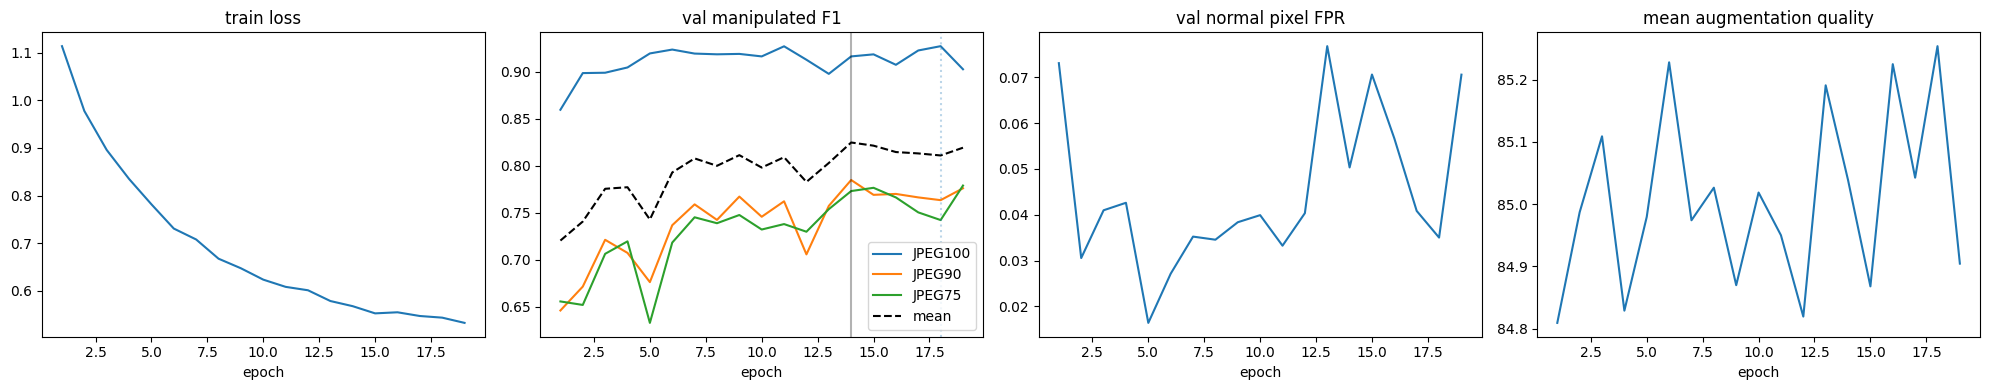

,selection,epoch,val_f1_q100,val_f1_q90,val_f1_q75,val_f1_mean,val_normal_fpr
0,best_mean,14,0.916334,0.784948,0.773189,0.824824,0.050333
1,best_q100,18,0.927227,0.763528,0.742361,0.811039,0.035017


학습 epoch 수: 19 / 전체 학습·검증 시간(분): 51.8
두 기준의 선택 epoch가 다름


In [8]:
history = pd.read_csv(run_root / "history.csv")
done = json.loads((run_root / "done.json").read_text())
figure, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].plot(history.epoch, history.train_loss)
axes[0].set_title("train loss")
for quality in config["val_qualities"]:
    axes[1].plot(history.epoch, history[f"val_f1_q{quality}"], label=f"JPEG{quality}")
axes[1].plot(history.epoch, history.val_f1_mean, "k--", label="mean")
axes[1].axvline(done["best_mean_epoch"], color="k", alpha=0.3)
axes[1].axvline(done["best_q100_epoch"], color="tab:blue", alpha=0.3, linestyle=":")
axes[1].set_title("val manipulated F1")
axes[1].legend()
axes[2].plot(history.epoch, history.val_normal_fpr)
axes[2].set_title("val normal pixel FPR")
axes[3].plot(history.epoch, history.aug_q_mean)
axes[3].set_title("mean augmentation quality")
for axis in axes:
    axis.set_xlabel("epoch")
plt.tight_layout()
plt.show()

columns = ["epoch", "val_f1_q100", "val_f1_q90", "val_f1_q75", "val_f1_mean", "val_normal_fpr"]
selected = history.set_index("epoch").loc[[done["best_mean_epoch"], done["best_q100_epoch"]]].reset_index()[columns]
selected.insert(0, "selection", ["best_mean", "best_q100"])
with pd.option_context("display.float_format", "{:.6f}".format):
    display(selected)
print("학습 epoch 수:", done["epochs_run"], "/ 전체 학습·검증 시간(분):",
      round((history.train_seconds.sum() + history.val_seconds.sum()) / 60, 1))
print("두 기준의 선택 epoch가 같음" if done["best_mean_epoch"] == done["best_q100_epoch"] else "두 기준의 선택 epoch가 다름")

## 7. 테스트 평가

테스트 셀은 모델별로 나눠져 있어 따로 실행할 수 있음. 각 셀은 결과를 Drive의 하위 폴더에 `test_rows.csv`와 `done.json`(체크포인트 SHA-256 포함)으로 남기고, 다시 실행하면 같은 체크포인트의 결과를 불러오기만 함. test 결과로 설정을 바꾸지 않음.

### 7-1. 007 대표 결과(`best_mean`)

공유 Drive 보관본을 원본과 대조하고(실패했으면 다시 복사), 경로·선택 epoch·크기·SHA-256을 출력한 뒤 테스트함.

In [9]:
def load_model(path):
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    model = ResNet50UNet(6).to(device)
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    return model, checkpoint


def run_test(tag, checkpoint_path, records):
    out_dir = run_root / tag
    out_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_hash = sha256(checkpoint_path)
    marker = out_dir / "done.json"
    if marker.is_file():
        saved = json.loads(marker.read_text())
        if saved["checkpoint_sha256"] == checkpoint_hash and saved["config_hash"] == config_hash:
            print(f"[{tag}] 저장된 테스트 결과 사용 (epoch {saved['epoch']})")
            return pd.read_csv(out_dir / "test_rows.csv")
    model, checkpoint = load_model(checkpoint_path)
    start = time.perf_counter()
    rows = evaluate(model, records)
    seconds = time.perf_counter() - start
    rows.to_csv(out_dir / "test_rows.csv", index=False)
    marker.write_text(json.dumps(dict(epoch=int(checkpoint["epoch"]), checkpoint=str(checkpoint_path),
                                      checkpoint_sha256=checkpoint_hash, config_hash=config_hash,
                                      images=len(rows), seconds=seconds), indent=1))
    print(f"[{tag}] epoch {checkpoint['epoch']}, test {len(rows)}장 평가 {seconds:.0f}s")
    del model
    torch.cuda.empty_cache()
    return rows


def show_summary(rows, title):
    print(title)
    with pd.option_context("display.float_format", "{:.6f}".format, "display.max_rows", None, "display.width", 200):
        display(summarize(rows))


done = json.loads((run_root / "done.json").read_text())
best_mean_path = run_root / "best_mean.pt"
if not shared_ckpt_path.is_file() or sha256(shared_ckpt_path) != sha256(best_mean_path):
    print("공유 Drive 보관본이 없거나 다름. 다시 복사함")
    verified_copy(best_mean_path, shared_ckpt_path)
shared_epoch = torch.load(shared_ckpt_path, map_location="cpu", weights_only=False)["epoch"]
assert shared_epoch == done["best_mean_epoch"]
print("공유 체크포인트:", shared_ckpt_path)
print("선택 epoch:", shared_epoch, "/ 크기:", f"{shared_ckpt_path.stat().st_size / 1024**2:.1f} MiB", "/ SHA-256:", sha256(shared_ckpt_path))

rows_mean = run_test("test_best_mean", best_mean_path, test_records)
show_summary(rows_mean, f"007 best_mean (epoch {done['best_mean_epoch']})")

공유 체크포인트: /content/drive/MyDrive/AI_Forensics/project/models/checkpoints/rgb_ela_unet/EXP_kimjihwan_007_rgb_ela_unet_grid_break_best.pt
선택 epoch: 14 / 크기: 124.4 MiB / SHA-256: f934eac345ebf0a285393fb3bed0bedc7bfd7d191e47d99e1acd750eaae546db
[test_best_mean] epoch 14, test 4305장 평가 92s
007 best_mean (epoch 14)


,dataset,kind,variant,images,pixel_f1,iou,normal_pixel_fpr
0,AutoSplice,normal,original,228,NaN,NaN,0.050651
1,AutoSplice,manipulated,JPEG100,335,0.933075,0.885618,NaN
2,AutoSplice,manipulated,JPEG90,335,0.811570,0.721106,NaN
3,AutoSplice,manipulated,JPEG75,335,0.804796,0.713913,NaN
4,CocoGlide,normal,JPEG100_444,512,NaN,NaN,0.921624
5,CocoGlide,manipulated,JPEG100_444,512,0.366923,0.262798,NaN
6,CocoGlide,normal,JPEG90_444,512,NaN,NaN,0.637361
7,CocoGlide,manipulated,JPEG90_444,512,0.384882,0.281475,NaN
8,CocoGlide,normal,JPEG75_444,512,NaN,NaN,0.599730
9,CocoGlide,manipulated,JPEG75_444,512,0.400238,0.293281,NaN


### 7-2. 007 기준 통일 확인(`best_q100`)

004와 같은 기준(val JPEG100 F1)으로 고른 epoch를 테스트함. 7-1과 같은 epoch면 7-1 결과를 그대로 씀.

In [10]:
done = json.loads((run_root / "done.json").read_text())
if done["best_q100_epoch"] == done["best_mean_epoch"]:
    rows_q100 = pd.read_csv(run_root / "test_best_mean" / "test_rows.csv")
    print(f"best_q100도 epoch {done['best_q100_epoch']}로 같음. 7-1 결과를 사용함")
else:
    rows_q100 = run_test("test_best_q100", run_root / "best_q100.pt", test_records)
show_summary(rows_q100, f"007 best_q100 (epoch {done['best_q100_epoch']})")

[test_best_q100] epoch 18, test 4305장 평가 88s
007 best_q100 (epoch 18)


,dataset,kind,variant,images,pixel_f1,iou,normal_pixel_fpr
0,AutoSplice,normal,original,228,NaN,NaN,0.034673
1,AutoSplice,manipulated,JPEG100,335,0.938897,0.895583,NaN
2,AutoSplice,manipulated,JPEG90,335,0.781771,0.689931,NaN
3,AutoSplice,manipulated,JPEG75,335,0.774480,0.683880,NaN
4,CocoGlide,normal,JPEG100_444,512,NaN,NaN,0.900283
5,CocoGlide,manipulated,JPEG100_444,512,0.364434,0.260034,NaN
6,CocoGlide,normal,JPEG90_444,512,NaN,NaN,0.701771
7,CocoGlide,manipulated,JPEG90_444,512,0.363001,0.260787,NaN
8,CocoGlide,normal,JPEG75_444,512,NaN,NaN,0.637819
9,CocoGlide,manipulated,JPEG75_444,512,0.373874,0.269653,NaN


### 7-3. 비교 기준(004·005) 불러오기

005 실행 폴더에 저장된 결과를 불러옴. 004는 AutoSplice를 004 노트북 저장값, CocoGlide를 005 노트북의 재평가 값으로 씀. 005는 `best_mean`(epoch 10)의 test 결과임. 005 폴더에 결과 파일이 없거나 체크포인트 SHA-256이 다르면 같은 체크포인트로 다시 평가해 007 폴더(`reference_*`)에 저장하고, 005 노트북에 저장된 출력값과 대조함.

In [13]:
ref_checkpoint_path = ref004_dir / "best.pt"
ref005_checkpoint_path = ref005_dir / "best_mean.pt"
coco_records = [r for r in test_records if r["dataset"] == "CocoGlide"]


def saved_or_rerun(tag, path, records):
    marker = ref005_dir / tag / "done.json"
    if marker.is_file() and json.loads(marker.read_text())["checkpoint_sha256"] == sha256(path):
        print(f"{tag}: 005 폴더의 저장 결과 사용")
        return pd.read_csv(ref005_dir / tag / "test_rows.csv")
    print(f"{tag}: 005 폴더에 저장 결과가 없어 체크포인트로 다시 평가함(007 폴더의 reference_{tag}/에 저장)")
    return run_test(f"reference_{tag}", path, records)


print("004 체크포인트:", ref_checkpoint_path, "/ SHA-256:", sha256(ref_checkpoint_path))
print("005 체크포인트:", ref005_checkpoint_path, "/ epoch",
      torch.load(ref005_checkpoint_path, map_location="cpu", weights_only=False)["epoch"], "/ SHA-256:", sha256(ref005_checkpoint_path))
ref_saved = pd.read_csv(ref004_dir / "test_rows.csv")
rows_ref = pd.concat([ref_saved[ref_saved.dataset == "AutoSplice"], saved_or_rerun("ref_004_cocoglide", ref_checkpoint_path, coco_records)],
                     ignore_index=True)
rows_005 = saved_or_rerun("test_best_mean", ref005_checkpoint_path, test_records)

# 005 노트북에 저장된 출력값과 대조(다시 평가한 경우 재현 확인용)
expected = [("004", rows_ref, "CocoGlide", "manipulated", "JPEG100_444", "f1", 0.361086),
            ("004", rows_ref, "CocoGlide", "normal", "JPEG100_444", "fpr", 0.975685),
            ("005", rows_005, "AutoSplice", "manipulated", "JPEG100", "f1", 0.913669),
            ("005", rows_005, "CocoGlide", "manipulated", "JPEG75_444", "f1", 0.400454),
            ("005", rows_005, "CocoGlide", "normal", "JPEG100_444", "fpr", 0.957112)]
for model_name, rows, dataset, kind, variant, column, value in expected:
    actual = rows[(rows.dataset == dataset) & (rows.kind == kind) & (rows.variant == variant)][column].mean()
    print(f"{model_name} {dataset} {variant} {kind} {column}: 005 노트북 출력 {value:.6f} / 지금 {actual:.6f} / 차이 {actual - value:+.1e}")
show_summary(rows_ref, "004 (증강 없음)")
show_summary(rows_005, "005 best_mean (JPEG 증강)")
os.sync()

004 체크포인트: /content/drive/MyDrive/AI_Forensics_runs/kimjihwan/EXP_kimjihwan_004_rgb_ela_unet_baseline/bce_dice/best.pt / SHA-256: 598c72389cfd0e93bd577d70b3b4c3428f6e75c6fe682a3641b1db2bc73c773b
005 체크포인트: /content/drive/MyDrive/AI_Forensics_runs/kimjihwan/EXP_kimjihwan_005_rgb_ela_unet_jpeg_aug/best_mean.pt / epoch 3 / SHA-256: cb49321175f5b815c03d755346338f573efb7694620fca65017754da27b9c25e
ref_004_cocoglide: 005 폴더에 저장 결과가 없어 체크포인트로 다시 평가함(007 폴더의 reference_ref_004_cocoglide/에 저장)
[reference_ref_004_cocoglide] epoch 25, test 3072장 평가 57s
test_best_mean: 005 폴더에 저장 결과가 없어 체크포인트로 다시 평가함(007 폴더의 reference_test_best_mean/에 저장)
[reference_test_best_mean] epoch 3, test 4305장 평가 86s
004 CocoGlide JPEG100_444 manipulated f1: 005 노트북 출력 0.361086 / 지금 0.361086 / 차이 -1.0e-07
004 CocoGlide JPEG100_444 normal fpr: 005 노트북 출력 0.975685 / 지금 0.975685 / 차이 -5.9e-08
005 AutoSplice JPEG100 manipulated f1: 005 노트북 출력 0.913669 / 지금 0.877198 / 차이 -3.6e-02
005 CocoGlide JPEG75_444 manipulated f1: 005 노트북 

,dataset,kind,variant,images,pixel_f1,iou,normal_pixel_fpr
0,AutoSplice,normal,original,228,NaN,NaN,0.000934
1,AutoSplice,manipulated,JPEG100,335,0.971787,0.946339,NaN
2,AutoSplice,manipulated,JPEG90,335,0.004701,0.002771,NaN
3,AutoSplice,manipulated,JPEG75,335,0.007563,0.004829,NaN
4,CocoGlide,normal,JPEG100_444,512,NaN,NaN,0.975685
5,CocoGlide,manipulated,JPEG100_444,512,0.361086,0.258608,NaN
6,CocoGlide,normal,JPEG90_444,512,NaN,NaN,0.265555
7,CocoGlide,manipulated,JPEG90_444,512,0.170326,0.112671,NaN
8,CocoGlide,normal,JPEG75_444,512,NaN,NaN,0.280365
9,CocoGlide,manipulated,JPEG75_444,512,0.236084,0.158642,NaN


005 best_mean (JPEG 증강)


,dataset,kind,variant,images,pixel_f1,iou,normal_pixel_fpr
0,AutoSplice,normal,original,228,NaN,NaN,0.347330
1,AutoSplice,manipulated,JPEG100,335,0.877198,0.813175,NaN
2,AutoSplice,manipulated,JPEG90,335,0.770155,0.668087,NaN
3,AutoSplice,manipulated,JPEG75,335,0.784808,0.683393,NaN
4,CocoGlide,normal,JPEG100_444,512,NaN,NaN,0.940679
5,CocoGlide,manipulated,JPEG100_444,512,0.365583,0.262491,NaN
6,CocoGlide,normal,JPEG90_444,512,NaN,NaN,0.396786
7,CocoGlide,manipulated,JPEG90_444,512,0.386105,0.282886,NaN
8,CocoGlide,normal,JPEG75_444,512,NaN,NaN,0.396720
9,CocoGlide,manipulated,JPEG75_444,512,0.417932,0.309649,NaN


## 8. 004·005·007 비교

품질별 점수와 JPEG100 대비 하락 폭을 나란히 비교함. 조작 이미지는 이미지별 F1 평균, 정상 이미지는 이미지별 픽셀 오탐률 평균임. 예측 그림은 test에서 고정 시드로 고른 AutoSplice·CocoGlide 조작 이미지 한 장씩을 JPEG100과 JPEG75로 보여 줌(005와 같은 표본).

model                                          004 no aug  005 best_mean  \
dataset    kind        metric     variant                                  
AutoSplice normal      normal FPR original       0.000934       0.347330   
           manipulated F1         JPEG100        0.971787       0.877198   
                                  JPEG90         0.004701       0.770155   
                                  JPEG75         0.007563       0.784808   
CocoGlide  normal      normal FPR JPEG100_444    0.975685       0.940679   
                                  JPEG90_444     0.265555       0.396786   
                                  JPEG75_444     0.280365       0.396720   
           manipulated F1         JPEG100_444    0.361086       0.365583   
                                  JPEG90_444     0.170326       0.386105   
                                  JPEG75_444     0.236084       0.417932   

model                                          007 best_mean  007 best_q100  
dataset    kind        metric     variant                                    
AutoSplice normal      normal FPR original          0.050651       0.034673  
           manipulated F1         JPEG100           0.933075       0.938897  
                                  JPEG90            0.811570       0.781771  
                                  JPEG75            0.804796       0.774480  
CocoGlide  normal      normal FPR JPEG100_444       0.921624       0.900283  
                                  JPEG90_444        0.637361       0.701771  
                                  JPEG75_444        0.599730       0.637819  
           manipulated F1         JPEG100_444       0.366923       0.364434  
                                  JPEG90_444        0.384882       0.363001  
                                  JPEG75_444        0.400238       0.373874

,dataset,model,f1_jpeg100,drop_to_90,drop_to_75
0,AutoSplice,004 no aug,+0.971787,-0.967087,-0.964224
1,AutoSplice,005 best_mean,+0.877198,-0.107043,-0.092390
2,AutoSplice,007 best_mean,+0.933075,-0.121505,-0.128279
3,AutoSplice,007 best_q100,+0.938897,-0.157126,-0.164417
4,CocoGlide,004 no aug,+0.361086,-0.190760,-0.125002
5,CocoGlide,005 best_mean,+0.365583,+0.020522,+0.052348
6,CocoGlide,007 best_mean,+0.366923,+0.017959,+0.033315
7,CocoGlide,007 best_q100,+0.364434,-0.001434,+0.009440


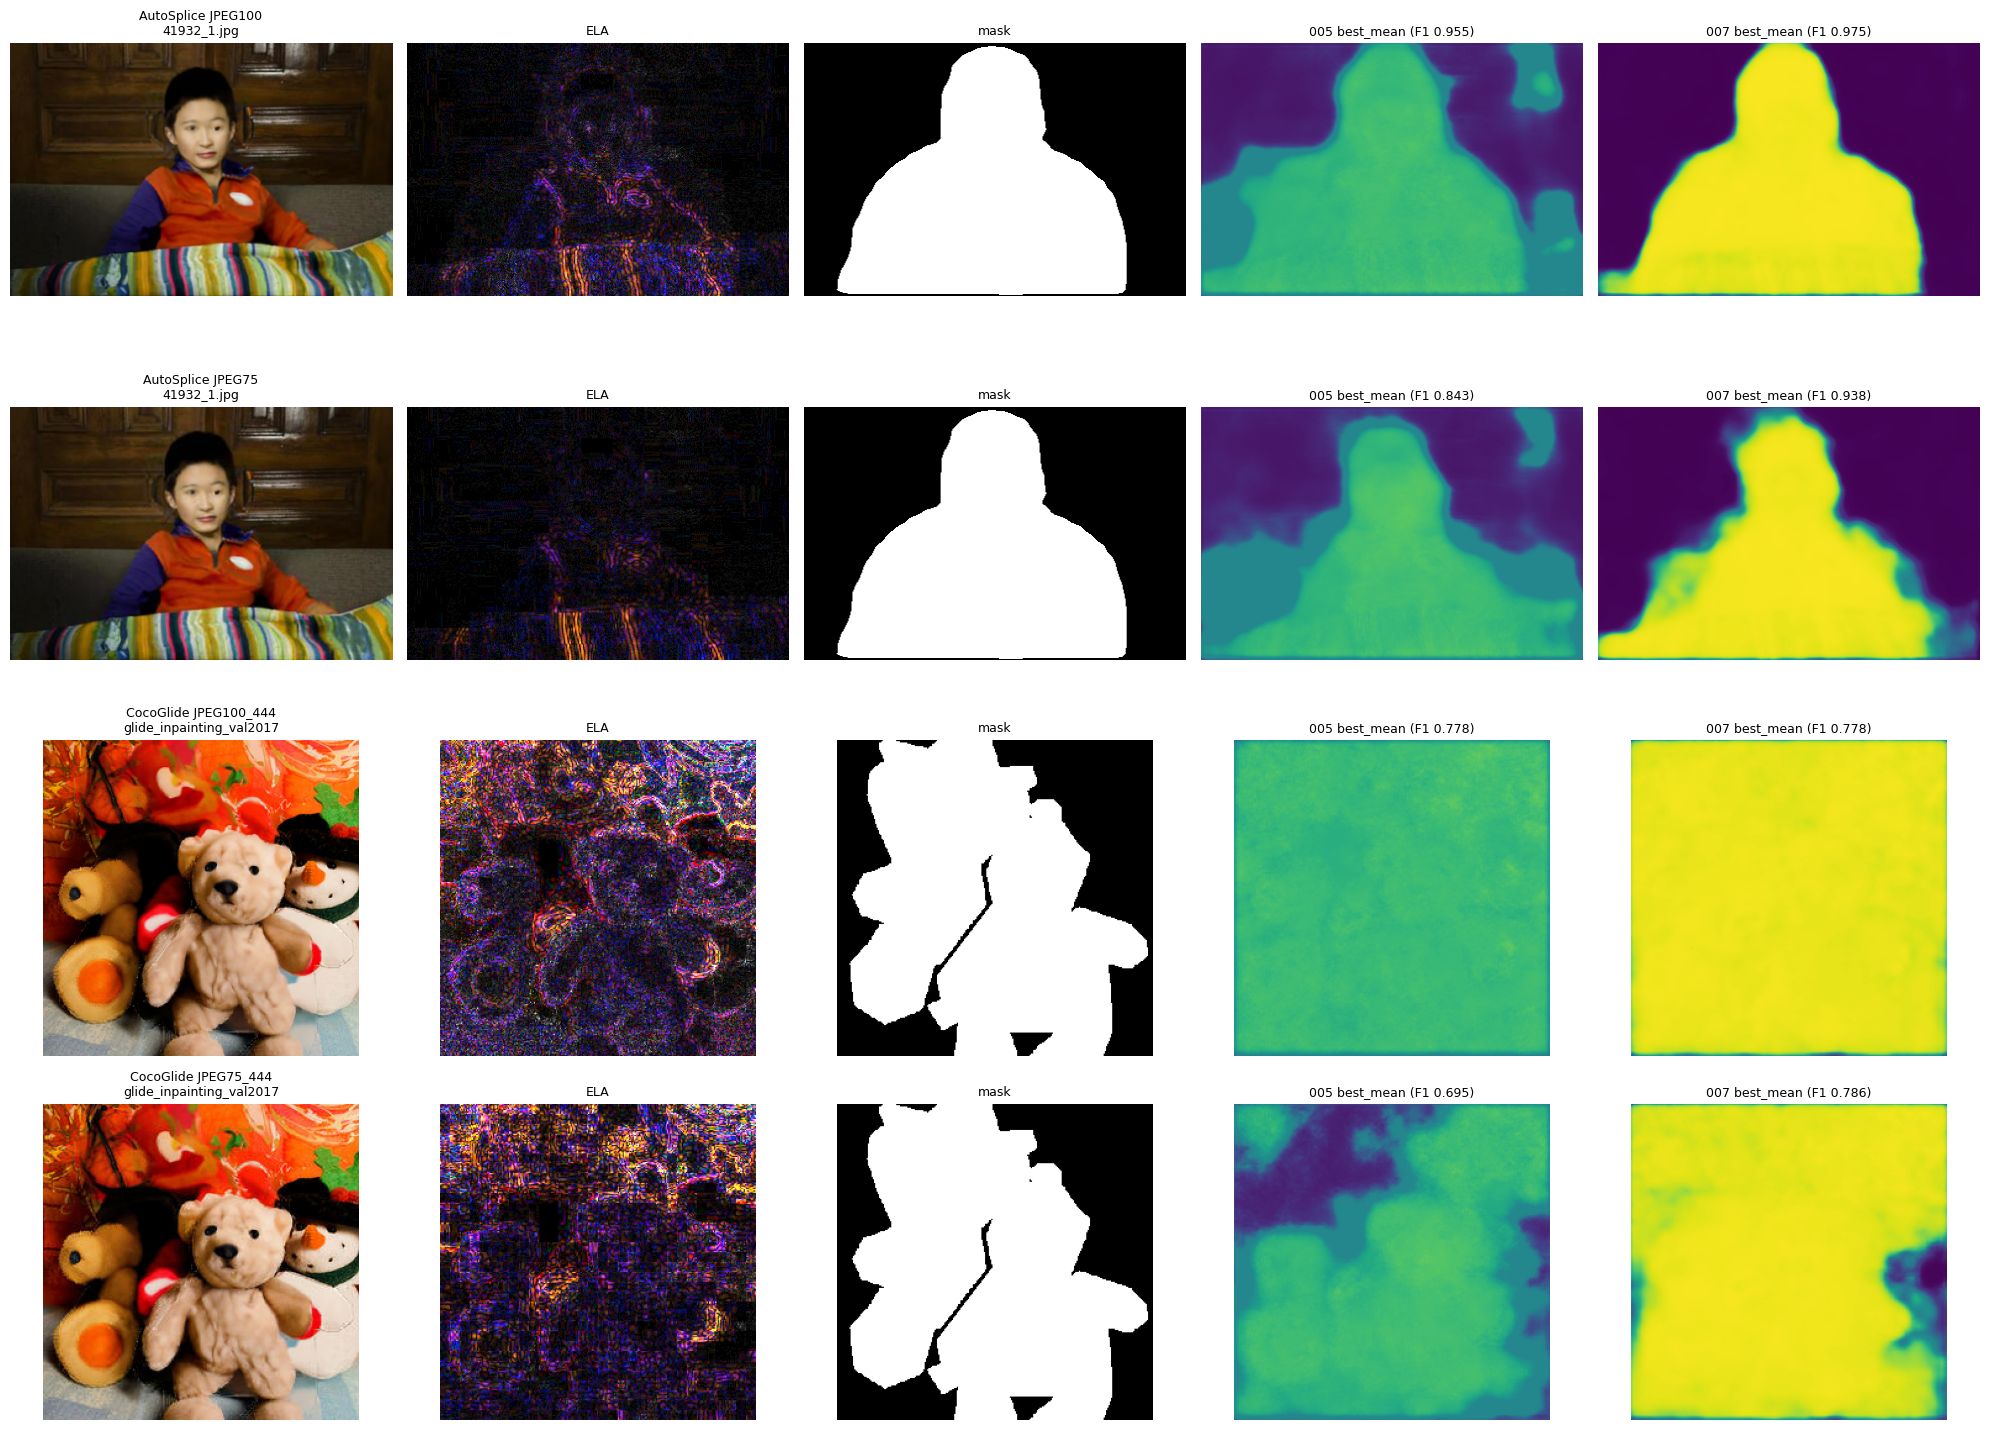

In [14]:
models = {"004 no aug": rows_ref, "005 best_mean": rows_005, "007 best_mean": rows_mean, "007 best_q100": rows_q100}
tables = []
for name, rows in models.items():
    summary = summarize(rows)
    summary["metric"] = np.where(summary.kind == "manipulated", "F1", "normal FPR")
    summary["score"] = summary.pixel_f1.fillna(summary.normal_pixel_fpr)
    summary["model"] = name
    tables.append(summary)
long = pd.concat(tables, ignore_index=True)
comparison = long.pivot_table(index=["dataset", "kind", "metric", "variant"], columns="model", values="score", sort=False)[list(models)]
with pd.option_context("display.float_format", "{:.6f}".format, "display.max_rows", None):
    display(comparison)

drops = []
for dataset, prefix, suffix in [("AutoSplice", "JPEG", ""), ("CocoGlide", "JPEG", "_444")]:
    for name in models:
        f1 = comparison.loc[(dataset, "manipulated", "F1")][name]
        base_score = f1[f"{prefix}100{suffix}"]
        drops.append(dict(dataset=dataset, model=name, f1_jpeg100=base_score,
                          drop_to_90=f1[f"{prefix}90{suffix}"] - base_score, drop_to_75=f1[f"{prefix}75{suffix}"] - base_score))
with pd.option_context("display.float_format", "{:+.6f}".format):
    display(pd.DataFrame(drops))

vis_rng = np.random.default_rng(seed)
lookup = {(r["dataset"], r["kind"], r["variant"], Path(r["image_path"]).name): r for r in test_records}
picks = []
for dataset, v100, v75 in [("AutoSplice", "JPEG100", "JPEG75"), ("CocoGlide", "JPEG100_444", "JPEG75_444")]:
    names = sorted(k[3] for k in lookup if k[0] == dataset and k[1] == "manipulated" and k[2] == v100)
    name = names[int(vis_rng.integers(len(names)))]
    picks += [lookup[(dataset, "manipulated", v100, name)], lookup[(dataset, "manipulated", v75, name)]]

vis_models = {"005 best_mean": load_model(ref005_checkpoint_path)[0], "007 best_mean": load_model(run_root / "best_mean.pt")[0]}
figure, axes = plt.subplots(len(picks), 3 + len(vis_models), figsize=(4 * (3 + len(vis_models)), 3.6 * len(picks)))
for row, record in enumerate(picks):
    rgb, mask = load_pair(record)
    panels = [(rgb, f"{record['dataset']} {record['variant']}\n{Path(record['image_path']).name[:24]}", None),
              (ela_of(rgb), "ELA", None), (mask, "mask", "gray")]
    for name, model in vis_models.items():
        probability = predict_full(model, rgb)
        prediction = (probability >= config["threshold"]).astype(np.uint8)
        tp, fp, fn, _ = confusion_counts(mask, prediction)
        panels.append((probability, f"{name} (F1 {pixel_f1(tp, fp, fn):.3f})", "viridis"))
    for column, (image, title, cmap) in enumerate(panels):
        axes[row, column].imshow(image, cmap=cmap, vmin=0 if cmap else None, vmax=1 if cmap else None)
        axes[row, column].set_title(title, fontsize=9)
        axes[row, column].axis("off")
plt.tight_layout()
plt.show()
del vis_models

## 9. 위치 정보 진단

005 10절과 같은 진단(픽셀 AUC, 마스크 섞기 F1, 쌍 차이 AUC, 전부 조작 기준선)을 007 두 체크포인트에 적용하고, 005 실행 폴더에 저장된 004·005 진단 결과와 나란히 비교함. 성공 기준은 CocoGlide JPEG100의 정상 오탐률·픽셀 AUC·쌍 차이 AUC임.

[004 no aug] 005 폴더에 진단 결과가 없어 다시 계산함(007 폴더의 diagnostics/에 저장)
[004 no aug] 500/2541 26s
[004 no aug] 1000/2541 52s
[004 no aug] 1500/2541 73s
[004 no aug] 2000/2541 93s
[004 no aug] 2500/2541 112s
[004 no aug] epoch 25, 조작 2541장 진단 114s
[005 best_mean] 005 폴더에 진단 결과가 없어 다시 계산함(007 폴더의 diagnostics/에 저장)
[005 best_mean] 500/2541 26s
[005 best_mean] 1000/2541 52s
[005 best_mean] 1500/2541 72s
[005 best_mean] 2000/2541 92s
[005 best_mean] 2500/2541 112s
[005 best_mean] epoch 3, 조작 2541장 진단 113s
[007 best_mean] 500/2541 26s
[007 best_mean] 1000/2541 53s
[007 best_mean] 1500/2541 74s
[007 best_mean] 2000/2541 95s
[007 best_mean] 2500/2541 115s
[007 best_mean] epoch 14, 조작 2541장 진단 117s
[007 best_q100] 500/2541 26s
[007 best_q100] 1000/2541 53s
[007 best_q100] 1500/2541 74s
[007 best_q100] 2000/2541 95s
[007 best_q100] 2500/2541 116s
[007 best_q100] epoch 18, 조작 2541장 진단 117s


images     f1  f1_shuffled_mask  f1_all_ones  pixel_auc  pair_diff_auc  pairs  prob_inside  prob_outside  pair_prob_mean  f1_gain_over_shuffled
dataset    variant     model                                                                                                                                                         
AutoSplice JPEG100     004 no aug        335 0.9718            0.7195       0.5404     0.9976         0.9930    335       0.9261        0.0283          0.0021                 0.2523
           JPEG90      004 no aug        335 0.0047            0.0043       0.5404     0.3252         0.4538    335       0.0035        0.0009          0.0021                 0.0004
           JPEG75      004 no aug        335 0.0076            0.0047       0.5404     0.3305         0.4941    335       0.0053        0.0010          0.0021                 0.0028
CocoGlide  JPEG100_444 004 no aug        512 0.3611            0.3560       0.3546     0.5624         0.4919    512       0.9364        0.8975          0.9154                 0.0051
           JPEG90_444  004 no aug        512 0.1703            0.1687       0.3546     0.4654         0.4385    512       0.2427        0.2396          0.2533                 0.0017
           JPEG75_444  004 no aug        512 0.2361            0.1908       0.3546     0.5518         0.4630    512       0.3429        0.2540          0.2681                 0.0453
AutoSplice JPEG100     005 best_mean     335 0.8772            0.6851       0.5404     0.9773         0.8485    335       0.6648        0.1845          0.3503                 0.1921
           JPEG90      005 best_mean     335 0.7702            0.6188       0.5404     0.9327         0.7122    335       0.6031        0.2013          0.3503                 0.1513
           JPEG75      005 best_mean     335 0.7848            0.6336       0.5404     0.9311         0.7367    335       0.6206        0.2164          0.3503                 0.1512
CocoGlide  JPEG100_444 005 best_mean     512 0.3656            0.3570       0.3546     0.6022         0.4654    512       0.6630        0.6332          0.6454                 0.0086
           JPEG90_444  005 best_mean     512 0.3861            0.2676       0.3546     0.6655         0.5434    512       0.4926        0.3765          0.3926                 0.1185
           JPEG75_444  005 best_mean     512 0.4179            0.2809       0.3546     0.7103         0.5694    512       0.5223        0.3694          0.3922                 0.1370
AutoSplice JPEG100     007 best_mean     335 0.9331            0.7043       0.5404     0.9916         0.9772    335       0.9267        0.0710          0.0554                 0.2288
           JPEG90      007 best_mean     335 0.8116            0.6452       0.5404     0.9487         0.9185    335       0.8355        0.1453          0.0554                 0.1664
           JPEG75      007 best_mean     335 0.8048            0.6339       0.5404     0.9485         0.9192    335       0.8039        0.1203          0.0554                 0.1709
CocoGlide  JPEG100_444 007 best_mean     512 0.3669            0.3504       0.3546     0.6359         0.5142    512       0.9331        0.8561          0.8723                 0.0166
           JPEG90_444  007 best_mean     512 0.3849            0.3110       0.3546     0.6933         0.5944    512       0.7766        0.6028          0.6054                 0.0739
           JPEG75_444  007 best_mean     512 0.4002            0.3111       0.3546     0.7161         0.6078    512       0.7721        0.5623          0.5695                 0.0891
AutoSplice JPEG100     007 best_q100     335 0.9389            0.7025       0.5404     0.9905         0.9766    335       0.9182        0.0609          0.0408                 0.2364
           JPEG90      007 best_q100     335 0.7818            0.6191       0.5404     0.9273         0.9013    335       0.7747        0.1313          0.0408                 0.1627
           JPEG75      007 best_q1

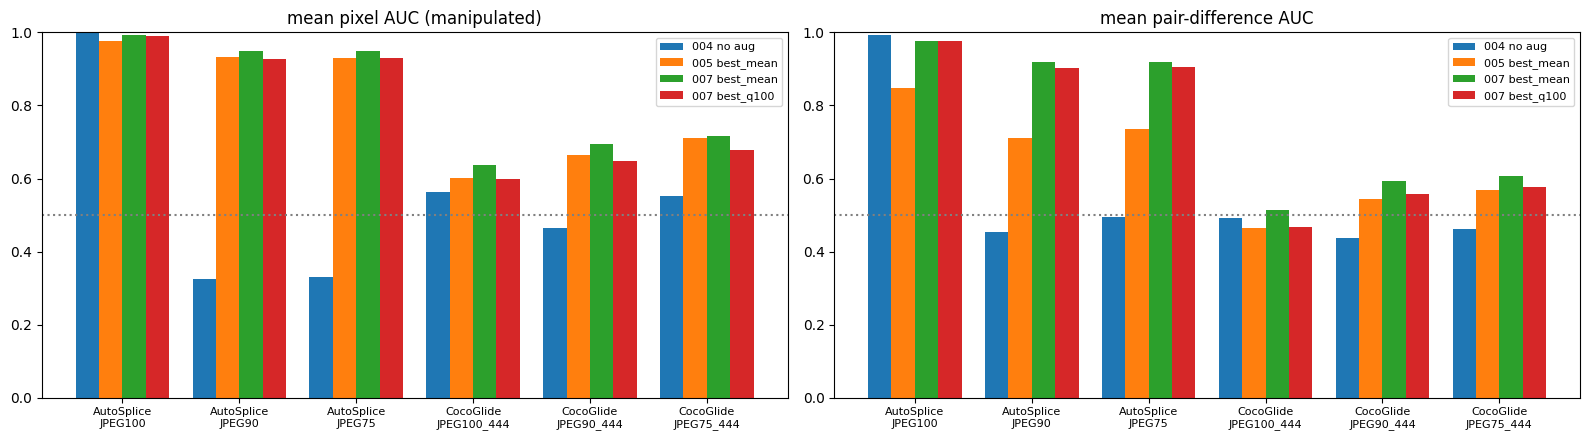

In [15]:
diagnostic_models = {"007 best_mean": run_root / "best_mean.pt", "007 best_q100": run_root / "best_q100.pt"}
diagnostic_dir = run_root / "diagnostics"
diagnostic_dir.mkdir(parents=True, exist_ok=True)
manipulated_test = [r for r in test_records if r["kind"] == "manipulated"]
normal_test = {}
for record in test_records:
    if record["kind"] == "normal":
        key = (record["dataset"], record["original_id"], record["variant"] if record["dataset"] == "CocoGlide" else "original")
        normal_test[key] = record
groups = {}
for record in manipulated_test:
    groups.setdefault((record["dataset"], record["variant"]), []).append(record)
shuffled_mask_of = {}
for members in groups.values():
    members = sorted(members, key=lambda r: str(r["input_path"]))
    for index, record in enumerate(members):
        shuffled_mask_of[str(record["input_path"])] = members[(index + 1) % len(members)]["mask_path"]


def pixel_auc(score, mask, bins=1000):
    inside, outside = score[mask > 0], score[mask == 0]
    if inside.size == 0 or outside.size == 0:
        return np.nan
    low, high = float(score.min()), float(score.max())
    if high <= low:
        return 0.5
    edges = np.linspace(low, high, bins + 1)
    count_in = np.histogram(inside, edges)[0].astype(np.float64)
    count_out = np.histogram(outside, edges)[0].astype(np.float64)
    below_out = np.concatenate([[0.0], np.cumsum(count_out)[:-1]])
    return float((count_in * (below_out + 0.5 * count_out)).sum() / (inside.size * outside.size))


def f1_against(prediction, mask):
    tp, fp, fn, _ = confusion_counts(mask, prediction)
    return pixel_f1(tp, fp, fn)


def diagnose(name, checkpoint_path):
    out_path = diagnostic_dir / f"{name.replace(' ', '_')}.csv"
    marker = diagnostic_dir / f"{name.replace(' ', '_')}.json"
    checkpoint_hash = sha256(checkpoint_path)
    if marker.is_file() and json.loads(marker.read_text())["checkpoint_sha256"] == checkpoint_hash:
        print(f"[{name}] 저장된 진단 결과 사용")
        return pd.read_csv(out_path)
    model, checkpoint = load_model(checkpoint_path)
    rows, start = [], time.perf_counter()
    for index, record in enumerate(manipulated_test):
        rgb, mask = load_pair(record)
        probability = predict_full(model, rgb)
        prediction = (probability >= config["threshold"]).astype(np.uint8)
        other = load_binary_mask(shuffled_mask_of[str(record["input_path"])], foreground_value=config["mask_foreground"])
        if other.shape != mask.shape:
            other = np.array(Image.fromarray(other).resize((mask.shape[1], mask.shape[0]), Image.NEAREST))
        row = dict(model=name, epoch=int(checkpoint["epoch"]), dataset=record["dataset"], variant=record["variant"],
                   image=Path(record["image_path"]).name, mask_ratio=float((mask > 0).mean()),
                   f1=f1_against(prediction, mask), f1_shuffled_mask=f1_against(prediction, other),
                   f1_all_ones=pixel_f1(int((mask > 0).sum()), int((mask == 0).sum()), 0),
                   pixel_auc=pixel_auc(probability, mask),
                   prob_inside=float(probability[mask > 0].mean()) if (mask > 0).any() else np.nan,
                   prob_outside=float(probability[mask == 0].mean()) if (mask == 0).any() else np.nan,
                   pair_prob_mean=np.nan, pair_diff_auc=np.nan)
        pair_key = (record["dataset"], record["original_id"], record["variant"] if record["dataset"] == "CocoGlide" else "original")
        pair = normal_test.get(pair_key)
        if pair is not None:
            pair_rgb, _ = load_pair(pair)
            if pair_rgb.shape == rgb.shape:
                pair_probability = predict_full(model, pair_rgb)
                row.update(pair_prob_mean=float(pair_probability.mean()),
                           pair_diff_auc=pixel_auc(probability - pair_probability, mask))
        rows.append(row)
        if (index + 1) % 500 == 0:
            print(f"[{name}] {index + 1}/{len(manipulated_test)} {time.perf_counter() - start:.0f}s")
    frame = pd.DataFrame(rows)
    frame.to_csv(out_path, index=False)
    marker.write_text(json.dumps(dict(checkpoint=str(checkpoint_path), checkpoint_sha256=checkpoint_hash,
                                      epoch=int(checkpoint["epoch"]), images=len(frame),
                                      seconds=time.perf_counter() - start), indent=1))
    print(f"[{name}] epoch {checkpoint['epoch']}, 조작 {len(frame)}장 진단 {time.perf_counter() - start:.0f}s")
    del model
    torch.cuda.empty_cache()
    return frame


reference_diagnostics = []
for name, path in [("004 no aug", ref_checkpoint_path), ("005 best_mean", ref005_checkpoint_path)]:
    marker = ref005_dir / "diagnostics" / f"{name.replace(' ', '_')}.json"
    if marker.is_file() and json.loads(marker.read_text())["checkpoint_sha256"] == sha256(path):
        print(f"[{name}] 005 폴더의 진단 결과 사용")
        reference_diagnostics.append(pd.read_csv(ref005_dir / "diagnostics" / f"{name.replace(' ', '_')}.csv"))
    else:
        print(f"[{name}] 005 폴더에 진단 결과가 없어 다시 계산함(007 폴더의 diagnostics/에 저장)")
        reference_diagnostics.append(diagnose(name, path))
diagnostics = pd.concat(reference_diagnostics + [diagnose(name, path) for name, path in diagnostic_models.items()],
                        ignore_index=True)
diagnostic_models = {"004 no aug": None, "005 best_mean": None, **diagnostic_models}
diagnostic_summary = diagnostics.groupby(["dataset", "variant", "model"], sort=False).agg(
    images=("image", "size"), f1=("f1", "mean"), f1_shuffled_mask=("f1_shuffled_mask", "mean"),
    f1_all_ones=("f1_all_ones", "mean"), pixel_auc=("pixel_auc", "mean"),
    pair_diff_auc=("pair_diff_auc", "mean"), pairs=("pair_diff_auc", "count"),
    prob_inside=("prob_inside", "mean"), prob_outside=("prob_outside", "mean"), pair_prob_mean=("pair_prob_mean", "mean"))
diagnostic_summary["f1_gain_over_shuffled"] = diagnostic_summary.f1 - diagnostic_summary.f1_shuffled_mask
with pd.option_context("display.float_format", "{:.4f}".format, "display.max_rows", None, "display.width", 250):
    display(diagnostic_summary)

figure, axes = plt.subplots(1, 2, figsize=(16, 4.5))
labels = [f"{d}\n{v}" for d, v in groups]
for offset, name in enumerate(diagnostic_models):
    values = [diagnostics[(diagnostics.model == name) & (diagnostics.dataset == d) & (diagnostics.variant == v)] for d, v in groups]
    x_positions = np.arange(len(groups)) + (offset - 1.5) * 0.2
    axes[0].bar(x_positions, [g.pixel_auc.mean() for g in values], width=0.2, label=name)
    axes[1].bar(x_positions, [g.pair_diff_auc.mean() for g in values], width=0.2, label=name)
for axis, title in zip(axes, ["mean pixel AUC (manipulated)", "mean pair-difference AUC"]):
    axis.axhline(0.5, color="gray", linestyle=":")
    axis.set_xticks(np.arange(len(groups)), labels, fontsize=8)
    axis.set_ylim(0, 1)
    axis.set_title(title)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()
os.sync()

In [16]:
criteria = diagnostic_summary.loc[("CocoGlide", "JPEG100_444")][["pixel_auc", "pair_diff_auc", "f1", "f1_shuffled_mask"]].copy()
normal_fpr = long[(long.dataset == "CocoGlide") & (long.kind == "normal") & (long.variant == "JPEG100_444")].set_index("model").score
criteria["normal_fpr"] = normal_fpr.reindex(criteria.index)
print("성공 기준 확인: CocoGlide JPEG100 (실행 전 고정한 기준, 판정은 보고서에서 함)")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(criteria)

성공 기준 확인: CocoGlide JPEG100 (실행 전 고정한 기준, 판정은 보고서에서 함)


/tmp/ipykernel_650/452959334.py:1: PerformanceWarning: indexing past lexsort depth may impact performance.
  criteria = diagnostic_summary.loc[("CocoGlide", "JPEG100_444")][["pixel_auc", "pair_diff_auc", "f1", "f1_shuffled_mask"]].copy()


,pixel_auc,pair_diff_auc,f1,f1_shuffled_mask,normal_fpr
model,,,,,
004 no aug,0.5624,0.4919,0.3611,0.3560,0.9757
005 best_mean,0.6022,0.4654,0.3656,0.3570,0.9407
007 best_mean,0.6359,0.5142,0.3669,0.3504,0.9216
007 best_q100,0.5995,0.4676,0.3644,0.3496,0.9003


## 10. 확인 결과와 검토 메모

아래 셀은 실행 범위를 요약함. 성공 기준 판정과 해석은 보고서에 작성함.

사람 검토 메모(실행 후 작성):

- 3·4절 증강 크롭과 ELA·정렬도 표(격자 깨기 후 안·밖 정렬도가 약 0.25인지):
- 6절 학습 곡선(품질별 val F1, val 정상 오탐률, 두 선택 기준의 epoch 차이):
- 8절 비교표와 예측 그림(AutoSplice 하락 폭, CocoGlide 오탐):
- 9절 진단(CocoGlide JPEG100 픽셀 AUC·쌍 차이 AUC·정상 오탐률):
- 특이사항(GPU 종류, 실행 시간, 끊김·재시작 여부, 공유 Drive 보관 결과 등):

In [17]:
done = json.loads((run_root / "done.json").read_text())
print("설정 해시:", config_hash)
print("실행 기록 폴더:", run_root)
print(f"학습 {done['epochs_run']} epoch, best_mean epoch {done['best_mean_epoch']} (val 평균 F1 {done['best_mean_f1']:.6f}), "
      f"best_q100 epoch {done['best_q100_epoch']} (val JPEG100 F1 {done['best_q100_f1']:.6f})")
print("공유 체크포인트:", shared_ckpt_path, "/ SHA-256:", sha256(shared_ckpt_path))
print("테스트 행 수: 007 best_mean", len(rows_mean), "/ 007 best_q100", len(rows_q100), "/ 005", len(rows_005), "/ 004", len(rows_ref))
print("실험 완료. test 결과로 설정을 바꾸지 않음")

설정 해시: bf084a937483
실행 기록 폴더: /content/drive/MyDrive/AI_Forensics_runs/kimjihwan/EXP_kimjihwan_007_rgb_ela_unet_grid_break
학습 19 epoch, best_mean epoch 14 (val 평균 F1 0.824824), best_q100 epoch 18 (val JPEG100 F1 0.927227)
공유 체크포인트: /content/drive/MyDrive/AI_Forensics/project/models/checkpoints/rgb_ela_unet/EXP_kimjihwan_007_rgb_ela_unet_grid_break_best.pt / SHA-256: f934eac345ebf0a285393fb3bed0bedc7bfd7d191e47d99e1acd750eaae546db
테스트 행 수: 007 best_mean 4305 / 007 best_q100 4305 / 005 4305 / 004 4305
실험 완료. test 결과로 설정을 바꾸지 않음


## 11. Drive 반영

Colab은 Drive 쓰기를 모아 두었다가 올리므로, 런타임이 바로 끊기면 마지막에 쓴 파일이 Drive에 남지 않을 수 있음(005 실행에서 결과 CSV·JSON이 빠진 원인으로 추정). 모든 셀을 실행한 뒤 이 셀을 실행해 Drive에 반영하고 연결을 해제함. 이후 다른 셀을 실행하려면 1번 셀부터 다시 실행함.

In [18]:
for path in sorted(run_root.rglob("*")):
    if path.is_file():
        print(path.relative_to(run_root), f"{path.stat().st_size / 1024:.0f} KiB")
drive.flush_and_unmount()
print("Drive 반영·연결 해제 완료")

best_mean.pt 127414 KiB
best_q100.pt 127414 KiB
diagnostics/004_no_aug.csv 570 KiB
diagnostics/004_no_aug.json 0 KiB
diagnostics/005_best_mean.csv 584 KiB
diagnostics/005_best_mean.json 0 KiB
diagnostics/007_best_mean.csv 588 KiB
diagnostics/007_best_mean.json 0 KiB
diagnostics/007_best_q100.csv 589 KiB
diagnostics/007_best_q100.json 0 KiB
done.json 0 KiB
history.csv 5 KiB
reference_ref_004_cocoglide/done.json 0 KiB
reference_ref_004_cocoglide/test_rows.csv 457 KiB
reference_test_best_mean/done.json 0 KiB
reference_test_best_mean/test_rows.csv 608 KiB
test_best_mean/done.json 0 KiB
test_best_mean/test_rows.csv 605 KiB
test_best_q100/done.json 0 KiB
test_best_q100/test_rows.csv 604 KiB
Drive 반영·연결 해제 완료


In [19]:
for path in sorted(Path("/content/checkpoints").rglob("*.pt")):
    epoch = torch.load(path, map_location="cpu", weights_only=False)["epoch"]
    print(path, "epoch", epoch, f"{path.stat().st_size / 1024**2:.0f} MiB", sha256(path)[:16])

/content/checkpoints/EXP_kimjihwan_007_rgb_ela_unet_grid_break/best_mean.pt epoch 14 124 MiB f934eac345ebf0a2
/content/checkpoints/EXP_kimjihwan_007_rgb_ela_unet_grid_break/best_q100.pt epoch 18 124 MiB 0860bb1afc47baa1
/content/checkpoints/EXP_kimjihwan_007_rgb_ela_unet_grid_break/last.pt epoch 19 373 MiB 16490a9f7764933f


In [21]:
import shutil
mount_point = Path("/content/drive")
if not os.path.ismount(mount_point):
    shutil.rmtree(mount_point, ignore_errors=True)   # 연결이 끊긴 상태에서 로컬에 잘못 생긴 폴더만 지움
    drive.mount(str(mount_point))
assert os.path.ismount(mount_point), "Drive가 연결돼야 함"

for path in [ref005_dir / "best_mean.pt", ref005_dir / "best_q100.pt",
             project_root / "models/checkpoints/rgb_ela_unet/EXP_kimjihwan_005_rgb_ela_unet_jpeg_aug_best.pt",
             run_root / "best_mean.pt", run_root / "best_q100.pt", shared_ckpt_path]:
    if path.is_file():
        print(path.name, "epoch", torch.load(path, map_location="cpu", weights_only=False)["epoch"], sha256(path)[:16])
    else:
        print(path.name, "없음")

for name in ["best_mean.pt", "best_q100.pt"]:
    print("개인 폴더:", name, verified_copy(local_ckpt_root / name, run_root / name)[:16])
print("공유 폴더:", verified_copy(local_ckpt_root / "best_mean.pt", shared_ckpt_path)[:16])
drive.flush_and_unmount()
print("Drive 반영·연결 해제 완료")

Mounted at /content/drive
best_mean.pt epoch 3 cb49321175f5b815
best_q100.pt epoch 2 2c5bf1d88ced501c
EXP_kimjihwan_005_rgb_ela_unet_jpeg_aug_best.pt epoch 3 cb49321175f5b815
best_mean.pt epoch 14 f934eac345ebf0a2
best_q100.pt epoch 18 0860bb1afc47baa1
EXP_kimjihwan_007_rgb_ela_unet_grid_break_best.pt epoch 14 f934eac345ebf0a2
개인 폴더: best_mean.pt f934eac345ebf0a2
개인 폴더: best_q100.pt 0860bb1afc47baa1
공유 폴더: f934eac345ebf0a2
Drive 반영·연결 해제 완료
